# Quantum Patch Classifier — Task 3.1 (v3: Fixed Pipe Masking + Denoising Pipeline)

Classification of **pipe vs. background patches** using a VQC (PennyLane) and a classical SVM, comparing **Raw, CLAHE, MSRCR, UDCP, and Denoised** inputs.

### What v3 fixes compared with v2 (results from 28-09)

| Issue observed in v2 | Fix implemented in v3 |
|---|---|
| SAM propagation “swallowed” the water: Video1 frames 8–21 were labeled at ~100%; Video6 detected the water column instead of the pipe (≈15 out of 24 frames were incorrect). | **Keyframes for every problematic frame**, **bounding boxes** for narrow pipes, an **axis corridor** (polyline) to clip mask leakage into the sand, and a filter that retains only **components containing positive points**. Video6_0000, where the pipe is almost invisible, is kept for inference only. |
| The VQC remained below the SVM, and VQC LOVO accuracy was 0.33. | **Automatic selection of 8 features** from 17 candidate features using validation data, including features **normalized relative to the frame background** and **3×3 contextual features**. |
| No noise treatment was included. | The team’s **SOTA denoising pipeline** is incorporated (see Section 2b) and evaluated under the same criteria. |

### Implemented denoising methods from the SOTA/team presentations

| Source (team presentations) | Implementation in this notebook |
|---|---|
| CLAHE to homogenize spotlight illumination (Practical Solution 1) | CLAHE applied to the L channel (Lab) within the **Denoised** input |
| Glare / bright-spot removal (Sheet #8) | Detection of saturated bright spots + *inpainting* using the Telea method |
| Marine snow / heterogeneous noise at close range | Color **Non-Local Means** filtering |
| SP-UIQA: decoupling the pipe from the background using SAM priors | Guided SAM labels + **Δ features relative to the frame background** |
| Dual local + global encoder (Hosseini, Swin-T + EFS-Net) / multiresolution approach (DeepLab-FusionNet) | **Local features** from 16×16 patches + **contextual features** from a 48×48 neighborhood |
| RandomResizedCrop [0.3, 1.5] (DMSNet, Practical Solution 2) | Crop/zoom augmentation applied to **training** frames only; retained only if it improves validation performance |
| Prediction noise | 3×3 spatial smoothing and temporal map smoothing using an **EMA**, both **selected on validation data** |

Rules: the test set must never determine the filter, features, epoch, threshold, augmentation strategy, or post-processing procedure. **Review `tube_review.png` before reporting results.**

In [ ]:
%pip -q install pennylane torch gdown seaborn scikit-learn opencv-python-headless pandas joblib scipy segment-anything

In [ ]:
from pathlib import Path
import json, re, time, shutil, subprocess, sys, urllib.request
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2, gdown, torch, pennylane as qml, joblib
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, jaccard_score, confusion_matrix
torch.set_num_threads(2)
ROOT=Path("/content/quantum_patch_classifier")
DATA=ROOT/"data"
OUT=ROOT/("results_"+time.strftime("%Y%m%d_%H%M%S"))
OUT.mkdir(parents=True,exist_ok=True)
METHODS=["Crudos","CLAHE","MSRCR","UDCP","Antirruido"]   # Antirruido = pipeline de la sección 2b
FILE_METHODS=["Crudos","CLAHE","MSRCR","UDCP"]      # los que vienen de Drive
SEEDS=[17,42,101]

# --- Selección del tubo ---
LABEL_SOURCE="sam_prompted"      # "sam_prompted" (v2) | "drive_masks" (máscaras SAM originales de Drive, v1)
LABEL_VIDEOS=["DeepWater-Video1","DeepWater-Video6","DeepWater-Video7"]
# Video3 muestra casco/rejilla sin tubo visible -> solo inferencia (añadirlo aquí si el equipo lo considera tubo)
SAM_MODEL="vit_b"
SAM_URL="https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
SAM_DEVICE="cuda" if torch.cuda.is_available() else "cpu"   # en CPU tarda ~20 s/frame; en GPU <1 s
RECOMPUTE_TUBE_MASKS=False       # se recalcula solo si cambian los keyframes (hash)

# --- Parches ---
SIZE_W,SIZE_H,PATCH=160,96,16    # 16:9, rejilla 10×6 = 60 parches por frame
BACKGROUND_MAX,STRUCTURE_MIN=.05,.35
MIN_VALID=.8                     # parches con >20 % de borde negro/HUD se ignoran
SPLIT_MODE="temporal_per_video"  # "temporal_per_video" | "by_video"

# --- Criterio ---
BALANCE_BY_VIDEO=True            # True: cada video pesa igual (recomendado). False: criterio global (lo domina Video1)

# --- VQC ---
N_QUBITS,N_LAYERS=8,4
EPOCHS,PATIENCE,BATCH,LR=40,10,64,.03
RUN_AMPLITUDE_BASELINE=True      # VQC de v1 (amplitudes, 6 qubits, 2 capas) como línea base
N_RRC=1                          # copias RandomResizedCrop por frame de train (0 = desactivado)
RRC_SCALE=(.3,1.5)               # <1 acercamiento, >1 alejamiento (DMSNet / presentación)
NLM_H=5                          # fuerza del Non-Local Means (nieve marina)
CLAHE_CLIP,CLAHE_TILES=2.0,(8,8)
print("PennyLane:",qml.__version__,"| SAM en:",SAM_DEVICE,"| resultados:",OUT)

PennyLane: 0.45.1 | SAM en: cpu | resultados: /content/quantum_patch_classifier/results_20260929_155440


## 1. Download
Built-in Drive inventory: individual downloads by ID to bypass gdown's folder limit.
This is a snapshot; files added afterward are not automatically included. If Drive blocks access or reaches the quota, the process stops; it does not continue with a partial dataset.


In [ ]:
MANIFEST={
 "CLAHE": [
  {
   "id": "1fgDd2ePY84hz5fJqCxn3LCe_azrLiDSo",
   "name": "DeepWater-Video7_frame_0009.jpg"
  },
  {
   "id": "1knw3Wv3sDnuJehAC_8puU9jTte_1hEDr",
   "name": "DeepWater-Video7_frame_0008.jpg"
  },
  {
   "id": "1mcYPBxq4DdBCIoCxahcM4CHxzX-A7m5i",
   "name": "DeepWater-Video7_frame_0007.jpg"
  },
  {
   "id": "1oS34TsRkVoVrJZo_jmcFWeQdaam0QGNJ",
   "name": "DeepWater-Video7_frame_0006.jpg"
  },
  {
   "id": "1APHELeXCvOPQCjQi_vU_qrgF3gRPpDFv",
   "name": "DeepWater-Video7_frame_0005.jpg"
  },
  {
   "id": "187Poe2FupHQM9TBOZIAvbVGAqWgc3cX4",
   "name": "DeepWater-Video7_frame_0004.jpg"
  },
  {
   "id": "1xjmEnOACiW-uXFW4SztTNzMMrt-_etCH",
   "name": "DeepWater-Video7_frame_0003.jpg"
  },
  {
   "id": "1qwj9L-zYBlQRqpUwYTRXY6NpR6baKXER",
   "name": "DeepWater-Video7_frame_0002.jpg"
  },
  {
   "id": "1rlyaYfCA35gwv8-sYMjkcS5FEMOx1XzN",
   "name": "DeepWater-Video7_frame_0001.jpg"
  },
  {
   "id": "1xb4YiJOh79Nj4y4oVdLJqGWDiv-6W2Qb",
   "name": "DeepWater-Video7_frame_0000.jpg"
  },
  {
   "id": "1l-_2J7nvTvrB4J9mISfe2OjyijoTHIqw",
   "name": "DeepWater-Video6_frame_0023.jpg"
  },
  {
   "id": "1DDCc70I6ax9B0L5QO5w1g9d73ceGJjLE",
   "name": "DeepWater-Video6_frame_0022.jpg"
  },
  {
   "id": "1osGy1FBZAP3aAvC1YTAHlEUkglEAbAfM",
   "name": "DeepWater-Video6_frame_0021.jpg"
  },
  {
   "id": "16Q4ZEKd4gFjGpgjzlFnbLc_8P5qfK949",
   "name": "DeepWater-Video6_frame_0020.jpg"
  },
  {
   "id": "1xHhapiz5YVakF-7Rx4uWamzjEwa6-Xb-",
   "name": "DeepWater-Video6_frame_0019.jpg"
  },
  {
   "id": "1Ycz8mc2ojnPqbkdsS7BXkRDO11jpEJBc",
   "name": "DeepWater-Video6_frame_0018.jpg"
  },
  {
   "id": "1bp3Tzb9TP6NLXj63zjuZX6Ns7RkM4BNH",
   "name": "DeepWater-Video6_frame_0017.jpg"
  },
  {
   "id": "1OLiwWnTWeo9AFhg70HY7DFwhtbAeQ0yw",
   "name": "DeepWater-Video6_frame_0016.jpg"
  },
  {
   "id": "131kAobM-kW7D3Dr6uNWQLrgAeFdYdQzD",
   "name": "DeepWater-Video6_frame_0015.jpg"
  },
  {
   "id": "1xwMhlJ3U6wjYeeWkGMfy50h19vgtlfdz",
   "name": "DeepWater-Video6_frame_0014.jpg"
  },
  {
   "id": "1hGtMx4GgpvDmhzfPkKT4MnRITDvQ8u5T",
   "name": "DeepWater-Video6_frame_0013.jpg"
  },
  {
   "id": "1iB3QIbZdHC5M7nfg3dk3AcLmj_FEdFSM",
   "name": "DeepWater-Video6_frame_0012.jpg"
  },
  {
   "id": "12Go-uVisePOxyRTDNWaofGjI40csf2lG",
   "name": "DeepWater-Video6_frame_0011.jpg"
  },
  {
   "id": "1VM5Of8Pffb5ZbYXeA5l8lMIsTeRLxqAU",
   "name": "DeepWater-Video6_frame_0010.jpg"
  },
  {
   "id": "1sbThjJyCJXkI9sxLFwCVvaNuBiIpeNrc",
   "name": "DeepWater-Video6_frame_0009.jpg"
  },
  {
   "id": "1NtOevajFPz5ah7AqJgJJ7wihBvQArOao",
   "name": "DeepWater-Video6_frame_0008.jpg"
  },
  {
   "id": "1-xKD-MbvLcfAPkdT4XSYPnQIaIt8R9HJ",
   "name": "DeepWater-Video6_frame_0007.jpg"
  },
  {
   "id": "1Dr7PumjAvgbMbix7EBhHGuZDDOQnksAE",
   "name": "DeepWater-Video6_frame_0006.jpg"
  },
  {
   "id": "1RR1rdlm57okcm_V-ly8MDn9DF5v_bXKn",
   "name": "DeepWater-Video6_frame_0005.jpg"
  },
  {
   "id": "1CO51EbeqMXJXqZ-AB-o66E8SWrp2wYCG",
   "name": "DeepWater-Video6_frame_0004.jpg"
  },
  {
   "id": "1vLt5xqkgPT2_czy94KpHB1aJevRiM3o0",
   "name": "DeepWater-Video6_frame_0003.jpg"
  },
  {
   "id": "1ePT18nLxo9mNRU15gQ-3vUyjHTOH0B_s",
   "name": "DeepWater-Video6_frame_0002.jpg"
  },
  {
   "id": "129ePsg_ZUdrR81EhtczRDooOufpcPcvH",
   "name": "DeepWater-Video6_frame_0001.jpg"
  },
  {
   "id": "1YJPWlf-Hmd_w4fVH5mUOAu2mrCARb4_W",
   "name": "DeepWater-Video6_frame_0000.jpg"
  },
  {
   "id": "1J-Eyu6jBCJEcYk65paSwyapA9QtBJhLQ",
   "name": "DeepWater-Video3_frame_0048.jpg"
  },
  {
   "id": "1MNiiNSFpioUTex3DZWOzfGfuoTGMyBXf",
   "name": "DeepWater-Video3_frame_0047.jpg"
  },
  {
   "id": "1tX4DGDX9q-Fg_qMChrCvGAIIcIyZUWRW",
   "name": "DeepWater-Video3_frame_0046.jpg"
  },
  {
   "id": "1-_X7k0FS9-b2E6o5YjRYRIZNjPdwtsfz",
   "name": "DeepWater-Video3_frame_0045.jpg"
  },
  {
   "id": "1dYoEeeBewAzN4xC2IONfjoKbCa6zOPqG",
   "name": "DeepWater-Video3_frame_0044.jpg"
  },
  {
   "id": "1y42bW18fw4IiZgqNV1tQLnwxsfeZ-kEf",
   "name": "DeepWater-Video3_frame_0043.jpg"
  },
  {
   "id": "1Th1xpHyz_TwCUDR8sA99Hu9Z6FBmTXDP",
   "name": "DeepWater-Video3_frame_0042.jpg"
  },
  {
   "id": "1yZ-Y0AvYmRJASZUN7-obwYR0vGNr5UML",
   "name": "DeepWater-Video3_frame_0041.jpg"
  },
  {
   "id": "1xHrw92tJ_4d_2KWB_PwaoEwzISqqfIgR",
   "name": "DeepWater-Video3_frame_0040.jpg"
  },
  {
   "id": "1E3r6swCkMTC-3kMHqa4b7__CRJfnOZTE",
   "name": "DeepWater-Video3_frame_0039.jpg"
  },
  {
   "id": "1pL88VjQmDrymrzDEJRG6Bll1B7diuVQ_",
   "name": "DeepWater-Video3_frame_0038.jpg"
  },
  {
   "id": "1MOWQGUC21AbeDsaezKP1Xf-jqwwZrANV",
   "name": "DeepWater-Video3_frame_0037.jpg"
  },
  {
   "id": "1hSRhKiHaX6DFwfgXMzcLNdm73B236vGO",
   "name": "DeepWater-Video3_frame_0036.jpg"
  },
  {
   "id": "1HAF2gS0MPEeCvBPsglgK-We7nwKDXatD",
   "name": "DeepWater-Video3_frame_0035.jpg"
  },
  {
   "id": "1IlBYVEloKCYpcj72ndpyJIpsOWRd5kMk",
   "name": "DeepWater-Video3_frame_0034.jpg"
  },
  {
   "id": "13JCJ31DnvXZuAF-QzG2DtcbuHrwI4RXW",
   "name": "DeepWater-Video3_frame_0033.jpg"
  },
  {
   "id": "1FHHJRGuiJyEIlzDjorWpj_UsCy5yL9VU",
   "name": "DeepWater-Video3_frame_0032.jpg"
  },
  {
   "id": "1u3l6KzKQQS5qL9Zh8mEX2w_oOGjmf4nK",
   "name": "DeepWater-Video3_frame_0031.jpg"
  },
  {
   "id": "1O9Bow2tNp4HFanLsinxjL5f-zfZqRbLd",
   "name": "DeepWater-Video3_frame_0030.jpg"
  },
  {
   "id": "1XCCz6dsF6smdrALErmbSy0mzmcg3MTfb",
   "name": "DeepWater-Video3_frame_0029.jpg"
  },
  {
   "id": "1KnYdqyUXmx6NfcWZOGM8Pz4RjjxmlEzl",
   "name": "DeepWater-Video3_frame_0028.jpg"
  },
  {
   "id": "1cKB68MZFCI1J5pPhfpr1n4sS_vpWxtlc",
   "name": "DeepWater-Video3_frame_0027.jpg"
  },
  {
   "id": "1MWPQs9sHitYr7bXNUO0u2PRvCFPGn3KA",
   "name": "DeepWater-Video3_frame_0026.jpg"
  },
  {
   "id": "1XEvymdehM0E-hzBZEBhl3pbQXMeTQfIL",
   "name": "DeepWater-Video3_frame_0025.jpg"
  },
  {
   "id": "1k2v22CfngxiJarwb-yPQCJBfeYd679ZU",
   "name": "DeepWater-Video3_frame_0024.jpg"
  },
  {
   "id": "1C7CgOBdyCRZALEwJP6zCTQN2nZO0LjBG",
   "name": "DeepWater-Video3_frame_0023.jpg"
  },
  {
   "id": "1a3_RLSAg2AeZlPwfNd3cEK_qkJ87TKFe",
   "name": "DeepWater-Video3_frame_0022.jpg"
  },
  {
   "id": "1uaRmLIWdPdHs9dVfgPY0XSkid1duKEL_",
   "name": "DeepWater-Video3_frame_0021.jpg"
  },
  {
   "id": "1j8t8dYLh4naS1nZXQaELIZKspyGt1GZd",
   "name": "DeepWater-Video3_frame_0020.jpg"
  },
  {
   "id": "1_J579CTarl0T--fw76sqX5oTFW4GW2A9",
   "name": "DeepWater-Video3_frame_0019.jpg"
  },
  {
   "id": "1NIKis4qRZTuDSwVfOnK1IYsW6avn5Cj-",
   "name": "DeepWater-Video3_frame_0018.jpg"
  },
  {
   "id": "1mQc-hSTyRi-A5QiN8RHNgD3usXWGV-L6",
   "name": "DeepWater-Video3_frame_0017.jpg"
  },
  {
   "id": "1AW11Ofrgk7Eiicf8RBwNbvcRzolMLhW-",
   "name": "DeepWater-Video3_frame_0016.jpg"
  },
  {
   "id": "1FGFYN0r2hjF3WXMppshAXEM8PuJP1KaK",
   "name": "DeepWater-Video3_frame_0015.jpg"
  },
  {
   "id": "10l4FUjVnh3KleZj6tt7R2whLKoop9bG5",
   "name": "DeepWater-Video3_frame_0014.jpg"
  },
  {
   "id": "1T5JRpKkpzlCiYr6u10tJMdg1b8rM5xZV",
   "name": "DeepWater-Video3_frame_0013.jpg"
  },
  {
   "id": "1H48RmW3MogFjJApPlcmVZwMVWYtqW2Av",
   "name": "DeepWater-Video3_frame_0012.jpg"
  },
  {
   "id": "1dcupn-7UpTQkZz-vlQbejqsDpK5H2Aie",
   "name": "DeepWater-Video3_frame_0011.jpg"
  },
  {
   "id": "1WSkgv33WSWBWfS6xeAaWR5JqeZS_5fzo",
   "name": "DeepWater-Video3_frame_0010.jpg"
  },
  {
   "id": "1tqntt-rZjwhjFYr09qm1TFcUMoFhCM6T",
   "name": "DeepWater-Video3_frame_0009.jpg"
  },
  {
   "id": "1tBDhKp7FyREorrEb314Jj_YUAz_w0wWi",
   "name": "DeepWater-Video3_frame_0008.jpg"
  },
  {
   "id": "18AIvYqg_pe6KtxRjeyaYSHeX8L2W856q",
   "name": "DeepWater-Video3_frame_0007.jpg"
  },
  {
   "id": "1pvaHSjQuMq_wUm766mmDbo63mSWUjg7W",
   "name": "DeepWater-Video3_frame_0006.jpg"
  },
  {
   "id": "1hoeNVTokbPlCFBswy-Hj3hikM-4zPrPq",
   "name": "DeepWater-Video3_frame_0005.jpg"
  },
  {
   "id": "1GNnCM1Yf4wenmOHbTygvW1WtYfDYUz8t",
   "name": "DeepWater-Video3_frame_0004.jpg"
  },
  {
   "id": "1yrTMgbjEl-CSnBG_3cVXfguHB8v15UXW",
   "name": "DeepWater-Video3_frame_0003.jpg"
  },
  {
   "id": "1mJ-j12kdjRwujVvdtH8dn-JDmJ_LKhL6",
   "name": "DeepWater-Video3_frame_0002.jpg"
  },
  {
   "id": "1goGdSxxI6UB1W5S6X_dWWPZyQZF4xhDF",
   "name": "DeepWater-Video3_frame_0001.jpg"
  },
  {
   "id": "18JK_Yq0fxCWLywqohvBN95G2XdnjUyGL",
   "name": "DeepWater-Video3_frame_0000.jpg"
  },
  {
   "id": "1vbqIWvXumDsgFC_jT9kyvD2E56POHo-q",
   "name": "DeepWater-Video1_frame_0021.jpg"
  },
  {
   "id": "1N3PdPsRYS8SSHrE5VCKlzc53PBY8z8T7",
   "name": "DeepWater-Video1_frame_0020.jpg"
  },
  {
   "id": "1xjLUbCwWMv1rIUcgviv5hGmNa4-_nhiv",
   "name": "DeepWater-Video1_frame_0019.jpg"
  },
  {
   "id": "1nIwFRiVMiLodsUGvLWumc4T-K0KThFFW",
   "name": "DeepWater-Video1_frame_0018.jpg"
  },
  {
   "id": "1uefSBqnSUjyNISczCGgFSvCGZScYwi1l",
   "name": "DeepWater-Video1_frame_0017.jpg"
  },
  {
   "id": "1hjk2W_WpK1-bSo6SeHo3lfXmazLbF8mK",
   "name": "DeepWater-Video1_frame_0016.jpg"
  },
  {
   "id": "182DWIYjEVF_X64JzlFdTj99o1cML1lid",
   "name": "DeepWater-Video1_frame_0015.jpg"
  },
  {
   "id": "1ZEkmRxvZU4Qxx8P14oYxP2uhx2d0snPL",
   "name": "DeepWater-Video1_frame_0014.jpg"
  },
  {
   "id": "1O-XKeX2-0fb_pjVOcQRfWJGzna8d7oo2",
   "name": "DeepWater-Video1_frame_0013.jpg"
  },
  {
   "id": "17ALlJ0uaZu2o-kVN5RgKc9_XKJhWCITt",
   "name": "DeepWater-Video1_frame_0012.jpg"
  },
  {
   "id": "11K610NL-yWC1SkpOD42Vv1MEL3TLH7Je",
   "name": "DeepWater-Video1_frame_0011.jpg"
  },
  {
   "id": "1n9zmXwQs7O3mBMikVoGSpmqcQfx6TkDH",
   "name": "DeepWater-Video1_frame_0010.jpg"
  },
  {
   "id": "1eZN2XC5ZkvPPIXelL5X3XhKiTcKTb29p",
   "name": "DeepWater-Video1_frame_0009.jpg"
  },
  {
   "id": "1Ua9gcECM3Lr-SwaWoK5xgxMHnxmNRXPE",
   "name": "DeepWater-Video1_frame_0008.jpg"
  },
  {
   "id": "1bV5dir7f65iZwiq8MLpWD497LCLCcGyx",
   "name": "DeepWater-Video1_frame_0007.jpg"
  },
  {
   "id": "1L7AHhSO7HezZSDpJq_LAfnWR0Lt1zaRP",
   "name": "DeepWater-Video1_frame_0006.jpg"
  },
  {
   "id": "1DPkyTT77_PD_X9TFyWFZSr7V_oInhYuN",
   "name": "DeepWater-Video1_frame_0005.jpg"
  },
  {
   "id": "1Zpb0i92sgBjV7lbUVgGjbYQSpl5YdvoZ",
   "name": "DeepWater-Video1_frame_0004.jpg"
  },
  {
   "id": "1BPx_adll5CyZcGTjG9Yt4Qaq2uTI0DHd",
   "name": "DeepWater-Video1_frame_0003.jpg"
  },
  {
   "id": "1hD0g9s8P-To8KqdceYk_EKYM2Zqch2Y-",
   "name": "DeepWater-Video1_frame_0002.jpg"
  },
  {
   "id": "1qiNv8AvTOJj_ybFNfzvqSI70y49L-00L",
   "name": "DeepWater-Video1_frame_0001.jpg"
  },
  {
   "id": "1TTGoVspb7WBP07TZUCQd5zkCk9jt9160",
   "name": "DeepWater-Video1_frame_0000.jpg"
  }
 ],
 "Crudos": [
  {
   "id": "1OywoanTlpuvq9JUQHW0rd4ZkIxVfXLme",
   "name": "DeepWater-Video3_frame_0048.jpg"
  },
  {
   "id": "1M03MZMLa9iZtjRbISCPuHAY5IDc_vk5F",
   "name": "DeepWater-Video3_frame_0047.jpg"
  },
  {
   "id": "1NbttKiIMhUx9ZqDW5psBgcQ3xiTSPyta",
   "name": "DeepWater-Video3_frame_0046.jpg"
  },
  {
   "id": "1k-wakm1adYq0Gzm6H49CKOjJ2u8YNN3N",
   "name": "DeepWater-Video3_frame_0045.jpg"
  },
  {
   "id": "1VfTtY_I1YKpqdBuogBJyleVu8HMNmwzi",
   "name": "DeepWater-Video3_frame_0044.jpg"
  },
  {
   "id": "1g39_bGMED45d2y8GBcufzhXpqXq3GYlo",
   "name": "DeepWater-Video3_frame_0043.jpg"
  },
  {
   "id": "1xy-C9x6BZtCZg_3idevaig1-PrNoG4Bt",
   "name": "DeepWater-Video3_frame_0042.jpg"
  },
  {
   "id": "1eDaMCLXfTrZ5GkdZrVtPZ9oHNk9iDdbg",
   "name": "DeepWater-Video3_frame_0041.jpg"
  },
  {
   "id": "11iPQzGuLa-9Lmx-udJxtQx_z0N1J9cyW",
   "name": "DeepWater-Video3_frame_0040.jpg"
  },
  {
   "id": "1K7Aw5SG5kT3nOZ-EA-QBocrxlE0bG6Hy",
   "name": "DeepWater-Video3_frame_0039.jpg"
  },
  {
   "id": "1OdP7CxZGsKzMtkQ6BZtGjgOATnnAXjKe",
   "name": "DeepWater-Video3_frame_0038.jpg"
  },
  {
   "id": "1VKqMNimqQne23LjfD_DigUdmnDbMRSs8",
   "name": "DeepWater-Video3_frame_0037.jpg"
  },
  {
   "id": "1q7V3hKPxpEbgI5f1U9VgnBuVBK2VdGNw",
   "name": "DeepWater-Video3_frame_0036.jpg"
  },
  {
   "id": "13uIo5ani5p8hftKNXAxp77CPFA0Dm5fQ",
   "name": "DeepWater-Video3_frame_0035.jpg"
  },
  {
   "id": "1kOmy5SH8TVs75Bq6D2md8IizwyrqNaBD",
   "name": "DeepWater-Video3_frame_0034.jpg"
  },
  {
   "id": "12nooJEM1X7r_wPuv3wNEGK1ej0GKU6Dw",
   "name": "DeepWater-Video3_frame_0033.jpg"
  },
  {
   "id": "1KRc9W3_xn1jHD1BfQryyqPZIkSYNHU6L",
   "name": "DeepWater-Video3_frame_0032.jpg"
  },
  {
   "id": "1S2llzOhAdGTAHXaPo4pHOWs5XN4bnEpU",
   "name": "DeepWater-Video3_frame_0031.jpg"
  },
  {
   "id": "1E7vpiK0vu1L73sQPUBlAEWAzHfgyAefC",
   "name": "DeepWater-Video3_frame_0030.jpg"
  },
  {
   "id": "1PARz-ocHl6pdHxsk8F9WtRMs7kQwuz1D",
   "name": "DeepWater-Video3_frame_0029.jpg"
  },
  {
   "id": "1BDhLCjITKm-pErkWpKd6tsWSnImgiUr8",
   "name": "DeepWater-Video3_frame_0028.jpg"
  },
  {
   "id": "17nCWQOUJvyiJM3dfcB6Z0dvdgDfEQoWZ",
   "name": "DeepWater-Video3_frame_0027.jpg"
  },
  {
   "id": "1ymA7AT5fNrbPS6LArPSZwLu5OjkwFtXK",
   "name": "DeepWater-Video3_frame_0026.jpg"
  },
  {
   "id": "1W2tI4c4DSHuqCo9f4iCBPXeygLz9U34y",
   "name": "DeepWater-Video3_frame_0025.jpg"
  },
  {
   "id": "12zetJ1Ys-6gPhmH138dxndZnV_gKO75x",
   "name": "DeepWater-Video3_frame_0024.jpg"
  },
  {
   "id": "1-2h7ToyELt0gX2LIcN_tBhR5eSvn-U1W",
   "name": "DeepWater-Video3_frame_0023.jpg"
  },
  {
   "id": "12yuD4zkQ7B7CmMnTR-b_QmmXxZ7d8-hR",
   "name": "DeepWater-Video3_frame_0022.jpg"
  },
  {
   "id": "1zYJQz-qmHzmgc-wYtOIEw4EjT0xZGwj-",
   "name": "DeepWater-Video3_frame_0021.jpg"
  },
  {
   "id": "1IXYRCA925tze3LhlBHhBxcH2WNcq-StC",
   "name": "DeepWater-Video3_frame_0020.jpg"
  },
  {
   "id": "1QRfvyrDbWIvv5dwtbnvC6AM7ZrrLjJU8",
   "name": "DeepWater-Video3_frame_0019.jpg"
  },
  {
   "id": "1leSzjsoPd_77NLevmqPEGxQcaKuOs3yG",
   "name": "DeepWater-Video3_frame_0018.jpg"
  },
  {
   "id": "1TiuJf8ONA4g3-KxQ0_PczYZbaJ0KT4M0",
   "name": "DeepWater-Video3_frame_0017.jpg"
  },
  {
   "id": "1s8oezqrKgkEk6zv1sDBbbXPLcMM7DoYF",
   "name": "DeepWater-Video3_frame_0016.jpg"
  },
  {
   "id": "1QF4lgMZNcGRj5daJ32BjWu5U0QNLuIeF",
   "name": "DeepWater-Video3_frame_0015.jpg"
  },
  {
   "id": "1_XsOm0TXQ3cRN-AP7Ma9pWoiw1MGAzYs",
   "name": "DeepWater-Video3_frame_0014.jpg"
  },
  {
   "id": "19n20zqYdMh5rUJFKiw-sP9hR3UH9c6ND",
   "name": "DeepWater-Video3_frame_0013.jpg"
  },
  {
   "id": "1tuVDlBewzhaN-EII0QyGZvEkkxzTdF3s",
   "name": "DeepWater-Video3_frame_0012.jpg"
  },
  {
   "id": "1h4_lkImUjqk7zevU_-2yvrIRriFOulFa",
   "name": "DeepWater-Video3_frame_0011.jpg"
  },
  {
   "id": "1m_pHZckjTFLHEfl6k9Et8DFPL_oZUssD",
   "name": "DeepWater-Video3_frame_0010.jpg"
  },
  {
   "id": "1mzX3ZYFTx00fL0sdbsFzLUS1djYJsvH7",
   "name": "DeepWater-Video3_frame_0009.jpg"
  },
  {
   "id": "1cpHKKWlmuxG0sYV4CQpc6_ihW3vzLSTG",
   "name": "DeepWater-Video3_frame_0008.jpg"
  },
  {
   "id": "1hcbdn9UT6oO8bLcAKWapqQRf0z2hX_jm",
   "name": "DeepWater-Video3_frame_0007.jpg"
  },
  {
   "id": "1UIUXxj89-A9Semt0U6iN1BG49h9yzdEh",
   "name": "DeepWater-Video3_frame_0006.jpg"
  },
  {
   "id": "1YQMzu7Gc3LdmaHtBTQNLB18iDIEYQbcB",
   "name": "DeepWater-Video3_frame_0005.jpg"
  },
  {
   "id": "1kBwBnuSWjSbO-cedg4kpWTmThGn_zx9U",
   "name": "DeepWater-Video3_frame_0004.jpg"
  },
  {
   "id": "1Kgp7oFc_vmd86sV99UM9vJ8j24CZURgv",
   "name": "DeepWater-Video3_frame_0003.jpg"
  },
  {
   "id": "1mhxhPiqjK2omwrzp1HGwJAfbK9_wJDXd",
   "name": "DeepWater-Video3_frame_0002.jpg"
  },
  {
   "id": "1Ka5y-XfNX7if3ah4HZKM-RIBtVN-N3HZ",
   "name": "DeepWater-Video3_frame_0001.jpg"
  },
  {
   "id": "1QhC5FR36RpqVdghL2X_Nxbws4tgKCQoV",
   "name": "DeepWater-Video3_frame_0000.jpg"
  },
  {
   "id": "1BUEBbTBDSKphPQW9X3qYR_Iv9oztEDSs",
   "name": "DeepWater-Video1_frame_0021.jpg"
  },
  {
   "id": "1pnXlOxMoznac4f2MYKF3CgFHNHrm2EWx",
   "name": "DeepWater-Video1_frame_0020.jpg"
  },
  {
   "id": "104MwBaq5zZPRnsEmMGMZbUJggKXNzN3c",
   "name": "DeepWater-Video1_frame_0019.jpg"
  },
  {
   "id": "1kyz6c3b9YBfp4BeciRGPBfyF9pwZ9FsH",
   "name": "DeepWater-Video1_frame_0018.jpg"
  },
  {
   "id": "11KSnvCSCQ3cisMnTvTBKYatMsX5DODGL",
   "name": "DeepWater-Video1_frame_0017.jpg"
  },
  {
   "id": "1mvbf7WblVGVxfa8ACM7ujF-0RxSqqGR1",
   "name": "DeepWater-Video1_frame_0016.jpg"
  },
  {
   "id": "1EHj65tD38am1fTKJQ5cR3znCtH_INZ_f",
   "name": "DeepWater-Video1_frame_0015.jpg"
  },
  {
   "id": "1f--TcZeTAG92iJAUZWrb09TIexDIFLEu",
   "name": "DeepWater-Video1_frame_0014.jpg"
  },
  {
   "id": "1gyI_L5FMp5v33ZPP0KFMqelxROQU5P1v",
   "name": "DeepWater-Video1_frame_0013.jpg"
  },
  {
   "id": "1Mp5OYhAalu53u-GWXNAOoZREEnEkAW4f",
   "name": "DeepWater-Video1_frame_0012.jpg"
  },
  {
   "id": "1h4fkzhPGfHtanQKnaefbySK86-f_10xc",
   "name": "DeepWater-Video1_frame_0011.jpg"
  },
  {
   "id": "1Td3sO8yzJypZy0IOW3FBm5_Xi8suVX1r",
   "name": "DeepWater-Video1_frame_0010.jpg"
  },
  {
   "id": "17d4XTzHhgLJlZxxksYzWuO9aS6WHGsGF",
   "name": "DeepWater-Video1_frame_0009.jpg"
  },
  {
   "id": "18zgHaiUpaUHTDhrn_ZfDAhkUBlad8zQ1",
   "name": "DeepWater-Video1_frame_0008.jpg"
  },
  {
   "id": "1aM4FVDsEIh48LOHhMcmH8Xn9oVatqQwV",
   "name": "DeepWater-Video1_frame_0007.jpg"
  },
  {
   "id": "1wnZUteGi7HOjB-ya58-oXzo_YZbsSvYW",
   "name": "DeepWater-Video1_frame_0006.jpg"
  },
  {
   "id": "14PsMCJ8TUmYW9kgq-_AOSOUqxAWNiQJh",
   "name": "DeepWater-Video1_frame_0005.jpg"
  },
  {
   "id": "1FK1lFBM3TEpNA328ujh9Q0iJYQAgpUUe",
   "name": "DeepWater-Video1_frame_0004.jpg"
  },
  {
   "id": "1nf4r1SocTd9d4cZdMKEffLj-FeEPbsP3",
   "name": "DeepWater-Video1_frame_0003.jpg"
  },
  {
   "id": "1zGsineLAOh7Vrak9dhGJUUqI6j6faPW6",
   "name": "DeepWater-Video1_frame_0002.jpg"
  },
  {
   "id": "1jODzJAkJq4mWqsLyJE-loU08dWm98zt8",
   "name": "DeepWater-Video1_frame_0001.jpg"
  },
  {
   "id": "1ZySxjXdkdYN-LyhQh9ePsBscJ5hDLwG2",
   "name": "DeepWater-Video1_frame_0000.jpg"
  },
  {
   "id": "1G0EXBM-xPgBgRaKddhMUzxXTv0XWKugC",
   "name": "DeepWater-Video6_frame_0023.jpg"
  },
  {
   "id": "1JlcJh-IKT5bO4WCGtvCB5n_UtGNDgsdu",
   "name": "DeepWater-Video6_frame_0022.jpg"
  },
  {
   "id": "1ScGXME9d9Xg-5jIHql9kN-myzHgu-aNy",
   "name": "DeepWater-Video6_frame_0021.jpg"
  },
  {
   "id": "1PRe9_EK--i8gr4RV2DOxURNOxti1vD2a",
   "name": "DeepWater-Video6_frame_0020.jpg"
  },
  {
   "id": "1FuOz_2RthbRRJtfF19ocVm6yDUlD0gkC",
   "name": "DeepWater-Video6_frame_0019.jpg"
  },
  {
   "id": "1brTx8WKtvS8pp-a1aDBIu9gZjxX_vJ3P",
   "name": "DeepWater-Video6_frame_0018.jpg"
  },
  {
   "id": "13IZhqw2n0q2f58et2kERK8oCDyl6Slzq",
   "name": "DeepWater-Video6_frame_0017.jpg"
  },
  {
   "id": "1qXsfLO9iP1zF9EhW7YTT6oZs6wqYKVgR",
   "name": "DeepWater-Video6_frame_0016.jpg"
  },
  {
   "id": "12lBEAIjUZGASHfn7ALulkq9TQ8ZnaCqZ",
   "name": "DeepWater-Video6_frame_0015.jpg"
  },
  {
   "id": "1v6bE-oRSpynkMx7vQBIKNb4z7Yvv0-4B",
   "name": "DeepWater-Video6_frame_0014.jpg"
  },
  {
   "id": "1nd2FegFZI0qr5VJ8CFafN7MlEXjLQAYq",
   "name": "DeepWater-Video6_frame_0013.jpg"
  },
  {
   "id": "1YDMRKS5ikzlNYVa1sUkKMrMFkmz2Nmb8",
   "name": "DeepWater-Video6_frame_0012.jpg"
  },
  {
   "id": "1barIh-XVC80S66Kpw3zGlEEQAOZOQl4B",
   "name": "DeepWater-Video6_frame_0011.jpg"
  },
  {
   "id": "1TTrcmaZ8TLaD6nyROczBrc96kUwQGvBN",
   "name": "DeepWater-Video6_frame_0010.jpg"
  },
  {
   "id": "1Aa8qBWS0__FnSjOL9jOMdV0iTyObVyll",
   "name": "DeepWater-Video6_frame_0009.jpg"
  },
  {
   "id": "1JoZbLMDQRl7bGCU-wMqLhgnqc8bv6y-1",
   "name": "DeepWater-Video6_frame_0008.jpg"
  },
  {
   "id": "1iSu2NysL4AhSVneNbn3oUfU6_rLIMAij",
   "name": "DeepWater-Video6_frame_0007.jpg"
  },
  {
   "id": "1skAstOmqfI-mvU8HMpmkMyrIGNZUerc9",
   "name": "DeepWater-Video6_frame_0006.jpg"
  },
  {
   "id": "161EGPFTQNOG6tW9WBlR_2M1zl0Q9_jQl",
   "name": "DeepWater-Video6_frame_0005.jpg"
  },
  {
   "id": "1XEO8Ozu93Wm51RW_9udGJMME4EZqGDuI",
   "name": "DeepWater-Video6_frame_0004.jpg"
  },
  {
   "id": "1ut5BrpgMycWEl06k5pNK5TZn4fn8eoNZ",
   "name": "DeepWater-Video6_frame_0003.jpg"
  },
  {
   "id": "1LEo5EnXC4ykJ7WVNBngpJgUFLhiYLIKZ",
   "name": "DeepWater-Video6_frame_0002.jpg"
  },
  {
   "id": "1Ai08T-z5NGhdU5IJkqO0cTeG4TZsxKJQ",
   "name": "DeepWater-Video6_frame_0001.jpg"
  },
  {
   "id": "1GWbMFbLd58Dt0krslp6l-OIGQbiDAEyn",
   "name": "DeepWater-Video6_frame_0000.jpg"
  },
  {
   "id": "12brTFO4tOwOY38ve_BpfEQn55E18LdFK",
   "name": "DeepWater-Video7_frame_0009.jpg"
  },
  {
   "id": "1yy4kANwvzcxn6ZDIbZVQ5Y26MwqUCOvS",
   "name": "DeepWater-Video7_frame_0008.jpg"
  },
  {
   "id": "1EEMH7GVo18t4719V1WndHRxFTz8H11xJ",
   "name": "DeepWater-Video7_frame_0007.jpg"
  },
  {
   "id": "1UZo5VyrtvKUe7YdsUJURAhh86TPSdNAL",
   "name": "DeepWater-Video7_frame_0006.jpg"
  },
  {
   "id": "1PhgScVroDeNnQeZp5i2tOKUSdKNi8vVu",
   "name": "DeepWater-Video7_frame_0005.jpg"
  },
  {
   "id": "1blP8qupsWhMSkEUvESM8gmSECc5oeNIv",
   "name": "DeepWater-Video7_frame_0004.jpg"
  },
  {
   "id": "17Mcgiq0qoGWshCSG2ln2ARWyZeg8xTLW",
   "name": "DeepWater-Video7_frame_0003.jpg"
  },
  {
   "id": "1TOIT3_inCCaGCTiUvRdUKOAXkXxvbsqr",
   "name": "DeepWater-Video7_frame_0002.jpg"
  },
  {
   "id": "1vunFJTmxYAj_ClxShKKE1sOF9kN16X-h",
   "name": "DeepWater-Video7_frame_0001.jpg"
  },
  {
   "id": "1-ATJufv237riBvr4Om1LYeYkKG_uf6ps",
   "name": "DeepWater-Video7_frame_0000.jpg"
  }
 ],
 "MSRCR": [
  {
   "id": "1p_Z_IzLM1UWFRNeHbXETOd6feJvZULEF",
   "name": "DeepWater-Video7_frame_0009.jpg"
  },
  {
   "id": "1vyn5VESdu_5lV5tp_lclWZZYinB1u0KA",
   "name": "DeepWater-Video7_frame_0008.jpg"
  },
  {
   "id": "1CdIwNq53YRi2Ndf57-WfxEy0u1S0C8_r",
   "name": "DeepWater-Video7_frame_0007.jpg"
  },
  {
   "id": "1pI3OzUGB9bhJU_2aUOdqYbTKuRlweyvz",
   "name": "DeepWater-Video7_frame_0006.jpg"
  },
  {
   "id": "1BDHhHKnPYmoPauF7hFIZTPpseiE_RLud",
   "name": "DeepWater-Video7_frame_0005.jpg"
  },
  {
   "id": "1yGJO2m0PVvwNcumU4hmIJQOsZ6GpCJ4v",
   "name": "DeepWater-Video7_frame_0004.jpg"
  },
  {
   "id": "1KucefBwJkKI51mNO0CayNxX4_yAKt-Gy",
   "name": "DeepWater-Video7_frame_0003.jpg"
  },
  {
   "id": "1VbK6Q4NRbJgNOvpIEMV4hL_BwzuSJ6Hh",
   "name": "DeepWater-Video7_frame_0002.jpg"
  },
  {
   "id": "1wteojhjvJOdkn8H9pArQC0D6z_L2abu8",
   "name": "DeepWater-Video7_frame_0001.jpg"
  },
  {
   "id": "1CCNySrgnqrJgkZZdNfmJrVT72BGQn1FR",
   "name": "DeepWater-Video7_frame_0000.jpg"
  },
  {
   "id": "1mRZDoLGo5G57r5e8TQ7GGCVrC_eyLg5U",
   "name": "DeepWater-Video6_frame_0023.jpg"
  },
  {
   "id": "1OpeK-oVgWfWDdfCfPSWXM47OxJU2D0cT",
   "name": "DeepWater-Video6_frame_0022.jpg"
  },
  {
   "id": "1oGhVKP_dtaTegmyXU12FZ1IcLcNw2Oml",
   "name": "DeepWater-Video6_frame_0021.jpg"
  },
  {
   "id": "1qvgA5HxzCCfRo793f_1KYJVSuNTQAmg0",
   "name": "DeepWater-Video6_frame_0020.jpg"
  },
  {
   "id": "1FIbhI9AuDNxNmUKf0WoyXvRN6pwW-VGk",
   "name": "DeepWater-Video6_frame_0019.jpg"
  },
  {
   "id": "1LL4UARZNmMFBnJa7bwIt-xCKo45Xuk_w",
   "name": "DeepWater-Video6_frame_0018.jpg"
  },
  {
   "id": "1K289_-CMUo0jLW6CvBeBIRFF1uILcDeY",
   "name": "DeepWater-Video6_frame_0017.jpg"
  },
  {
   "id": "1HkePamrkevr7znbDsRqAoRIGN2iXaLuE",
   "name": "DeepWater-Video6_frame_0016.jpg"
  },
  {
   "id": "18EMTCLdPCtDKz-40Y8U0x9olJo4-Mem5",
   "name": "DeepWater-Video6_frame_0015.jpg"
  },
  {
   "id": "1stDk_CBiPrHZXsgJHWdA59qKMNK98yxx",
   "name": "DeepWater-Video6_frame_0014.jpg"
  },
  {
   "id": "1LtCrZD3hy-4AMjEcKoU86Vf2npKsuJlz",
   "name": "DeepWater-Video6_frame_0013.jpg"
  },
  {
   "id": "16YRmFIm5pnChilD8YBlB0k3TlSDqIiOb",
   "name": "DeepWater-Video6_frame_0012.jpg"
  },
  {
   "id": "1xts9DJj_dgf0S_7hJjJqHeXOlh8Dg3eH",
   "name": "DeepWater-Video6_frame_0011.jpg"
  },
  {
   "id": "1xCs_z-pxHhYvjsKXL-i7g9AfNDiFW0bR",
   "name": "DeepWater-Video6_frame_0010.jpg"
  },
  {
   "id": "1E3nPE86cladfI21AN4Vty-ksIYdcVqaM",
   "name": "DeepWater-Video6_frame_0009.jpg"
  },
  {
   "id": "1n0w6uPt26xA-TRUE_1CvFC05WvUcZwON",
   "name": "DeepWater-Video6_frame_0008.jpg"
  },
  {
   "id": "1prRaYhFfRMrRveN2GZ_iKNvOqdqHlnJe",
   "name": "DeepWater-Video6_frame_0007.jpg"
  },
  {
   "id": "1xRr0JUQphv-NsuWQkN5VSYa-gIzpETen",
   "name": "DeepWater-Video6_frame_0006.jpg"
  },
  {
   "id": "14x0fvyFuhBwhRti8fi2SQH88GziEQkE1",
   "name": "DeepWater-Video6_frame_0005.jpg"
  },
  {
   "id": "1tV611h2rSL4zY8aY656o0s4i-ZQYavSw",
   "name": "DeepWater-Video6_frame_0004.jpg"
  },
  {
   "id": "1PfoNp93ByNTayh-aXoSTglGQ6QuFXE5K",
   "name": "DeepWater-Video6_frame_0003.jpg"
  },
  {
   "id": "1ItWtwcGO2sV_pKlR7CXcSmOpbBCK-LRd",
   "name": "DeepWater-Video6_frame_0002.jpg"
  },
  {
   "id": "13WSmo4SoGRORChfAT864moj2WCK3WS_T",
   "name": "DeepWater-Video6_frame_0001.jpg"
  },
  {
   "id": "16_6r8TDtj5V4lH016EwbAge5-bmKlLzW",
   "name": "DeepWater-Video6_frame_0000.jpg"
  },
  {
   "id": "1KTECYZIj5imyTRRmp9pTQzPgeD33-Wvp",
   "name": "DeepWater-Video3_frame_0048.jpg"
  },
  {
   "id": "1n4Saa3UjdMdGcoNsLrvoz2kYceg7SHBN",
   "name": "DeepWater-Video3_frame_0047.jpg"
  },
  {
   "id": "17T47tjD55Ep87NH7_XX4hhyspoHbPXqD",
   "name": "DeepWater-Video3_frame_0046.jpg"
  },
  {
   "id": "10jmyszGR7LPQuUMX3hLaoFHdOMVDfgWm",
   "name": "DeepWater-Video3_frame_0045.jpg"
  },
  {
   "id": "1pjivuu8KdhqOGu3xxQvSEYxf52Pauz06",
   "name": "DeepWater-Video3_frame_0044.jpg"
  },
  {
   "id": "1mWcX1QpcBXaVt0JrdQy6qscA6wF7UP2y",
   "name": "DeepWater-Video3_frame_0043.jpg"
  },
  {
   "id": "1It8NK9GPrnUopI2bD6VJ0gdK3tD0NCFK",
   "name": "DeepWater-Video3_frame_0042.jpg"
  },
  {
   "id": "1-Nx3I6y3AB1_Fuc-iLxAbvzXGwiLvWfh",
   "name": "DeepWater-Video3_frame_0041.jpg"
  },
  {
   "id": "1W7GhmGeTSWVuwcMY21nHD-MLQIQLio6M",
   "name": "DeepWater-Video3_frame_0040.jpg"
  },
  {
   "id": "1fUiB5Pu_9UaYT-t-kQWLsQm8Y826qjGQ",
   "name": "DeepWater-Video3_frame_0039.jpg"
  },
  {
   "id": "11tv1-53fdLaZXLWl8-eu2NoWtvKvDgs5",
   "name": "DeepWater-Video3_frame_0038.jpg"
  },
  {
   "id": "1G9MN7KFlr2TyUKKyDdMN-U1BQmi-j9dT",
   "name": "DeepWater-Video3_frame_0037.jpg"
  },
  {
   "id": "1QpzlndUA-nHaZGtCvoUUbYQqyef9Y6Pq",
   "name": "DeepWater-Video3_frame_0036.jpg"
  },
  {
   "id": "1McpJyi9vThrB_T_cp-nWCI_Ot0bmaoUL",
   "name": "DeepWater-Video3_frame_0035.jpg"
  },
  {
   "id": "1AMUlfOSxy7cTCtghigoqGJxaQJXTSNdB",
   "name": "DeepWater-Video3_frame_0034.jpg"
  },
  {
   "id": "1ghWbqTOEt4EZCvgRSRHTsZS5aB4Ixu0T",
   "name": "DeepWater-Video3_frame_0033.jpg"
  },
  {
   "id": "1FAmEPuif90Xnd2WffU9K68pHVpZ1j3IO",
   "name": "DeepWater-Video3_frame_0032.jpg"
  },
  {
   "id": "1HGRkT9Ly-yxRdUZkgzePu-E66Tlc8oPO",
   "name": "DeepWater-Video3_frame_0031.jpg"
  },
  {
   "id": "1HsdI52MBEoVk1QbTmtHBuNaY2aMrPieD",
   "name": "DeepWater-Video3_frame_0030.jpg"
  },
  {
   "id": "14TRYl3u-FWuofbmUA9Cf9zVXfXhqnluT",
   "name": "DeepWater-Video3_frame_0029.jpg"
  },
  {
   "id": "1rxMjdXJU4NDEAC7grSPD4UI8GyprSCGM",
   "name": "DeepWater-Video3_frame_0028.jpg"
  },
  {
   "id": "1NjM_33bm5tdTJM9SUPs8BWU6CZXgM7Jk",
   "name": "DeepWater-Video3_frame_0027.jpg"
  },
  {
   "id": "1rX9DsJF2frwqLBmqEJ0Be9a1xPsfd7wx",
   "name": "DeepWater-Video3_frame_0026.jpg"
  },
  {
   "id": "1Zmg55zCVdxUfZK0tAocFvaeZv6dKbYjr",
   "name": "DeepWater-Video3_frame_0025.jpg"
  },
  {
   "id": "1C2B04Zl0GYHfa_xIsDUPoP_X87givSVn",
   "name": "DeepWater-Video3_frame_0024.jpg"
  },
  {
   "id": "1WbvfpFUey4TnE9yxCtW8q2HEpgQCT6Iy",
   "name": "DeepWater-Video3_frame_0023.jpg"
  },
  {
   "id": "1ce_kVwIuQGSf7jC3MWyvE4WbFXc3RF01",
   "name": "DeepWater-Video3_frame_0022.jpg"
  },
  {
   "id": "18ZtUzIKcP8xTKIQJtXYVmBGn-y0g1Pui",
   "name": "DeepWater-Video3_frame_0021.jpg"
  },
  {
   "id": "1hI0SRqks6Tr5suz4z-KxOcZp0B3ghKlQ",
   "name": "DeepWater-Video3_frame_0020.jpg"
  },
  {
   "id": "1Wj95651kH5GGk7Ehx-ZdxOvfObnSPTBK",
   "name": "DeepWater-Video3_frame_0019.jpg"
  },
  {
   "id": "1269yyX2aE8B5cx7mPjuFBenzCiB3_b5J",
   "name": "DeepWater-Video3_frame_0018.jpg"
  },
  {
   "id": "1WcD4VUDSoI7GReH-o6RC3Sq7g8UJrZYh",
   "name": "DeepWater-Video3_frame_0017.jpg"
  },
  {
   "id": "1nKv35nPW1SuFea04ncEdnBcLz7cB3t0c",
   "name": "DeepWater-Video3_frame_0016.jpg"
  },
  {
   "id": "1HHDdcn_kcIk-oRhApB8S5zEWawZPgkFM",
   "name": "DeepWater-Video3_frame_0015.jpg"
  },
  {
   "id": "1xt5qAhzIWUrt9lwK2SSgZe29uOcvJbcB",
   "name": "DeepWater-Video3_frame_0014.jpg"
  },
  {
   "id": "1LHqPLEjMw3ZrYLMn0kcxWBROfsRk_4rH",
   "name": "DeepWater-Video3_frame_0013.jpg"
  },
  {
   "id": "1bd6RPVDcbR3RYv2X5dU1qIH4xa80Y13C",
   "name": "DeepWater-Video3_frame_0012.jpg"
  },
  {
   "id": "1SFySXlaWG_85mkdMYNYLTpVqQ2gEsd72",
   "name": "DeepWater-Video3_frame_0011.jpg"
  },
  {
   "id": "15YPn6PobBmdZF44RTmtBigQhYyJVuuX9",
   "name": "DeepWater-Video3_frame_0010.jpg"
  },
  {
   "id": "1M6c0mzk6bn_kJtfvo8h_g0lykzTDzdUw",
   "name": "DeepWater-Video3_frame_0009.jpg"
  },
  {
   "id": "1BoH2V_bFn5IjkfJ18-aJ1iRn1Yh2J4Gp",
   "name": "DeepWater-Video3_frame_0008.jpg"
  },
  {
   "id": "1n1bKcVGihALHiZoCY1fNej4AwvrI_zjQ",
   "name": "DeepWater-Video3_frame_0007.jpg"
  },
  {
   "id": "1WOj5Bv0JLM-ClgeciIjsJy_46afGjSl6",
   "name": "DeepWater-Video3_frame_0006.jpg"
  },
  {
   "id": "1jA_IKLVM7XnrOS8JNs2pLkvLQtWL67dm",
   "name": "DeepWater-Video3_frame_0005.jpg"
  },
  {
   "id": "1HdyBvvvD9PBSYNuOJXYCbqK8RTfyeeNs",
   "name": "DeepWater-Video3_frame_0004.jpg"
  },
  {
   "id": "1FNlPEkGGuqHqEaY_pVJygbDuV-ww2AP5",
   "name": "DeepWater-Video3_frame_0003.jpg"
  },
  {
   "id": "1xqGpuJJZyiziXOH6oDZFjOicqHYfm9Ze",
   "name": "DeepWater-Video3_frame_0002.jpg"
  },
  {
   "id": "1p6hIXA9NjJfbqlwnKIiAVIhWA9KhIq5H",
   "name": "DeepWater-Video3_frame_0001.jpg"
  },
  {
   "id": "133OvAH5P6iMK27sO-CT5SeXjzqoI43yi",
   "name": "DeepWater-Video3_frame_0000.jpg"
  },
  {
   "id": "1f0W2qeAucqeLjoBcrxw39_fvpsEnCoTl",
   "name": "DeepWater-Video1_frame_0021.jpg"
  },
  {
   "id": "1cf0R6LEbra7NEP7gflMmd4KY-Tynntvj",
   "name": "DeepWater-Video1_frame_0020.jpg"
  },
  {
   "id": "1R-XBi4bvG4GEBcRB0ewjkyLWlZjAdcj3",
   "name": "DeepWater-Video1_frame_0019.jpg"
  },
  {
   "id": "1oQ6T-dH9N4HpyopYy8L-KW4iPQxCtCnK",
   "name": "DeepWater-Video1_frame_0018.jpg"
  },
  {
   "id": "1Vbuq_SXBvJdnp7NE8AvH43sVrT1Bh6Xb",
   "name": "DeepWater-Video1_frame_0017.jpg"
  },
  {
   "id": "1QteNcCXxCW8V8Xx2aQe5sgSmxCnXC31C",
   "name": "DeepWater-Video1_frame_0016.jpg"
  },
  {
   "id": "18yryUxyEwchFggpNsdxEG3sopT7X5uHA",
   "name": "DeepWater-Video1_frame_0015.jpg"
  },
  {
   "id": "1X41pi1A_kXPdR1VooqJTSGTEeTlaASZU",
   "name": "DeepWater-Video1_frame_0014.jpg"
  },
  {
   "id": "16tgWGnNG0KSG5O3HIu_jFOXyrS8wsW13",
   "name": "DeepWater-Video1_frame_0013.jpg"
  },
  {
   "id": "1I8fyd-B0Yk_1DYjpJUkYeHv6573NSwDb",
   "name": "DeepWater-Video1_frame_0012.jpg"
  },
  {
   "id": "1u_oath6EP8W-OBH7HDq1UmBXWkZAe2Co",
   "name": "DeepWater-Video1_frame_0011.jpg"
  },
  {
   "id": "1-5abGe-rEb6YdtjdUYogHWDRztb-Lrmm",
   "name": "DeepWater-Video1_frame_0010.jpg"
  },
  {
   "id": "11hvh-25w0ZD8Q-ccSQwPB8IIFmE_AR3-",
   "name": "DeepWater-Video1_frame_0009.jpg"
  },
  {
   "id": "1r1XkJuVQjFUn1Nlzxekj7FDfLKK4B1l8",
   "name": "DeepWater-Video1_frame_0008.jpg"
  },
  {
   "id": "1AF6P1DkqhVL_iXsd-bsidi8huaLmSLca",
   "name": "DeepWater-Video1_frame_0007.jpg"
  },
  {
   "id": "11yGtVAnskh9IQ6Aw5wtBw8WSuiv_yhpL",
   "name": "DeepWater-Video1_frame_0006.jpg"
  },
  {
   "id": "1Flro2w4KvS3zWZMca5TbU4Y4rQ8aftpo",
   "name": "DeepWater-Video1_frame_0005.jpg"
  },
  {
   "id": "13i25MZeeWBFoLEO6fljZDhDLuK5aIdn9",
   "name": "DeepWater-Video1_frame_0004.jpg"
  },
  {
   "id": "1MiApHVAizyAJoQgz2G-7OnNgG2V4lw5P",
   "name": "DeepWater-Video1_frame_0003.jpg"
  },
  {
   "id": "18OrXBrckwVd5QPTF8vP8MEG7QUg9hygv",
   "name": "DeepWater-Video1_frame_0002.jpg"
  },
  {
   "id": "12FA72wxerCHXajo_u-_7gthwY7cGgGcl",
   "name": "DeepWater-Video1_frame_0001.jpg"
  },
  {
   "id": "1nvpOwPAwcANxgPjdr-VvMHRD0eK3btwY",
   "name": "DeepWater-Video1_frame_0000.jpg"
  }
 ],
 "Masks": [
  {
   "id": "1w6UQ9n1ohrTOtWuOyxICmdz96Xs1a7JF",
   "name": "DeepWater-Video1_frame_0019_mask.png"
  },
  {
   "id": "1v7a3Dnts2HVE_ArULzM8-3hkFxJbHHgr",
   "name": "DeepWater-Video1_frame_0018_mask.png"
  },
  {
   "id": "1l_tTReRmAfYL6V0qEy8uDqPfX_Y3Ii1N",
   "name": "DeepWater-Video1_frame_0017_mask.png"
  },
  {
   "id": "1IqVPN_5zNH8VgxV3xbAYO5DY2fYlsO8K",
   "name": "DeepWater-Video1_frame_0016_mask.png"
  },
  {
   "id": "1cwilZqIYLXMLir41tAnIq0PnVSaJQNlZ",
   "name": "DeepWater-Video1_frame_0015_mask.png"
  },
  {
   "id": "1Pgv0MF4ILk_IZ74_dZYMpX33X-oIsmgx",
   "name": "DeepWater-Video1_frame_0014_mask.png"
  },
  {
   "id": "14_kEReDxYwMeXzbT2ikCRIuYg4rOIGnu",
   "name": "DeepWater-Video1_frame_0013_mask.png"
  },
  {
   "id": "111FY32r7i3ZLI-kw3WaIC-3GYuV93b_B",
   "name": "DeepWater-Video1_frame_0012_mask.png"
  },
  {
   "id": "1j6RZ-1sBzVgObz1B1xwjUZKMcoSjpok1",
   "name": "DeepWater-Video1_frame_0011_mask.png"
  },
  {
   "id": "16ZnMuE327GtiWu5v72MIC6rLbtOfouK6",
   "name": "DeepWater-Video1_frame_0010_mask.png"
  },
  {
   "id": "1kbMt7EhMBebsRYE4TMt-BcmM3YyVxBUM",
   "name": "DeepWater-Video1_frame_0009_mask.png"
  },
  {
   "id": "1Wtl4daMwBRyMoxFFEkcd3VZ0sUY6O3Jx",
   "name": "DeepWater-Video1_frame_0008_mask.png"
  },
  {
   "id": "1N-7sfdSxPofZoGKZJdt5DMdvnK5Uz535",
   "name": "DeepWater-Video1_frame_0007_mask.png"
  },
  {
   "id": "14wOJBhlBbO2NTkYe4DcWG2XIGQI_ub9X",
   "name": "DeepWater-Video1_frame_0006_mask.png"
  },
  {
   "id": "11SMgAlHfGrIuWJCaTWiJLPzjFUG9ETn1",
   "name": "DeepWater-Video1_frame_0005_mask.png"
  },
  {
   "id": "1n7Eb_WHLqMgHndfpOmQcQ8QZp6GHVBWg",
   "name": "DeepWater-Video1_frame_0004_mask.png"
  },
  {
   "id": "1T32_MB5kY3hcTknC5ZY9t9fh0tIzHtTS",
   "name": "DeepWater-Video1_frame_0003_mask.png"
  },
  {
   "id": "14WoM_mvyn6HKoQOE5ptqBak160t5Q3WJ",
   "name": "DeepWater-Video1_frame_0002_mask.png"
  },
  {
   "id": "1TBUpJhUM2pF8G6y_b-_6WruxMl7Zq90u",
   "name": "DeepWater-Video1_frame_0001_mask.png"
  },
  {
   "id": "1PH7XodKRHcpM5UvUvHPwHSw6RAvozvfq",
   "name": "DeepWater-Video1_frame_0000_mask.png"
  }
 ],
 "UDCP": [
  {
   "id": "1CztyTjj_JgehMFTGj8KD7Jo2zpMVjaSt",
   "name": "DeepWater-Video7_frame_0009.jpg"
  },
  {
   "id": "1fo_ZGVdYrwje8n4QWkq4voXBxKVCKgOr",
   "name": "DeepWater-Video7_frame_0008.jpg"
  },
  {
   "id": "1GP8paMx_TfVY_11vSR-ZWpZ-bGCgToxb",
   "name": "DeepWater-Video7_frame_0007.jpg"
  },
  {
   "id": "1OWZwRFT10kuZTY7o-5OMkruGAiGQVvN4",
   "name": "DeepWater-Video7_frame_0006.jpg"
  },
  {
   "id": "1WTfgroI2Xfk_HEFWM0866ZB_ZJondjoT",
   "name": "DeepWater-Video7_frame_0005.jpg"
  },
  {
   "id": "1DzMEAsBxZIL8ersXKCtkWe5K3P1UBkA3",
   "name": "DeepWater-Video7_frame_0004.jpg"
  },
  {
   "id": "1Lb0rYzvpBdc-rNmRlTd7a3hH_uwaHZZk",
   "name": "DeepWater-Video7_frame_0003.jpg"
  },
  {
   "id": "1iSWQeYoOcv_ANqNkeJj1aK7oEAw4S1sU",
   "name": "DeepWater-Video7_frame_0002.jpg"
  },
  {
   "id": "1pn6AdhyXHYvsn6dtk9syYoA_tM18qWLv",
   "name": "DeepWater-Video7_frame_0001.jpg"
  },
  {
   "id": "11-17nU6NLSnC-66VHhuJzqAQvSaYs96a",
   "name": "DeepWater-Video7_frame_0000.jpg"
  },
  {
   "id": "1horRE_QCV_dal35zB3pd7RvoaDYnZR6K",
   "name": "DeepWater-Video6_frame_0023.jpg"
  },
  {
   "id": "1nRcbnNV6htFsSe8LPTg7-yINWGtfkKSL",
   "name": "DeepWater-Video6_frame_0022.jpg"
  },
  {
   "id": "1rKcIVZYiCRudvDR51B9Ti7dBP66wA0CY",
   "name": "DeepWater-Video6_frame_0021.jpg"
  },
  {
   "id": "1dsK2PevhtwbDZUWf7s2sDi2soSLDn38y",
   "name": "DeepWater-Video6_frame_0020.jpg"
  },
  {
   "id": "1HArOmW4csknwknLNkS8v6DHc6LbwDDbp",
   "name": "DeepWater-Video6_frame_0019.jpg"
  },
  {
   "id": "1CTmsa97QaNSyaTtKezjbQgzvVsLWL998",
   "name": "DeepWater-Video6_frame_0018.jpg"
  },
  {
   "id": "1vA82p8Pcj0K1KlFadW6n5dnoW7ie8h5q",
   "name": "DeepWater-Video6_frame_0017.jpg"
  },
  {
   "id": "1efEk5pkEvGZ4W_To8edV9rX2iOMJNpmt",
   "name": "DeepWater-Video6_frame_0016.jpg"
  },
  {
   "id": "1MzyvYKXni1yWzSfI5DXkPE2MSy-ZA54A",
   "name": "DeepWater-Video6_frame_0015.jpg"
  },
  {
   "id": "1RgFt45Mt48BSxkqX0o-saVrGB2rTKjOY",
   "name": "DeepWater-Video6_frame_0014.jpg"
  },
  {
   "id": "1wLMjc9KmoFyHUzUgJaTH0EW0QhfVREoy",
   "name": "DeepWater-Video6_frame_0013.jpg"
  },
  {
   "id": "112zUYppkDFW_sUAB0GPP3Hwt8qNrs3zy",
   "name": "DeepWater-Video6_frame_0012.jpg"
  },
  {
   "id": "1AuAqhzNZthZq6rNmshX7Linm0YEMxJsa",
   "name": "DeepWater-Video6_frame_0011.jpg"
  },
  {
   "id": "1sdEhmKDhQOB18Lnsp4GRQvAD6qDKEkT9",
   "name": "DeepWater-Video6_frame_0010.jpg"
  },
  {
   "id": "1wcj9QQMGcOuoNwSFpOyG2WId6bTSyz6S",
   "name": "DeepWater-Video6_frame_0009.jpg"
  },
  {
   "id": "1Ks5m8JXRY9SuH9VX4gWIOy7HcC-m8_1U",
   "name": "DeepWater-Video6_frame_0008.jpg"
  },
  {
   "id": "1Jy5Mv3RGJ8tVi2Qjn5W_JusK8Lz4-5G3",
   "name": "DeepWater-Video6_frame_0007.jpg"
  },
  {
   "id": "15gMOULzzM5joX3ESUgSWyItNC9IjU16c",
   "name": "DeepWater-Video6_frame_0006.jpg"
  },
  {
   "id": "1gcV4OzjoMJXyr_vCiskNqwfmnRAEIMbZ",
   "name": "DeepWater-Video6_frame_0005.jpg"
  },
  {
   "id": "1jCXMWZpyD2Cq9CJo3brsErtGvtZUIbmV",
   "name": "DeepWater-Video6_frame_0004.jpg"
  },
  {
   "id": "1iSq5r1w5pcINveCtKTQpXd3shHxf_8Rw",
   "name": "DeepWater-Video6_frame_0003.jpg"
  },
  {
   "id": "1A35KRNKs1JkryB7j_hIMe0Ub0oF_6942",
   "name": "DeepWater-Video6_frame_0002.jpg"
  },
  {
   "id": "1-2M11eI2---GbRMVXzHO-YW_03ikcO-S",
   "name": "DeepWater-Video6_frame_0001.jpg"
  },
  {
   "id": "1YJSA-HMHtnrazjM4RbHR3F7iJu8gMmbE",
   "name": "DeepWater-Video6_frame_0000.jpg"
  },
  {
   "id": "1vWhRI09znCyYEBZwbwne7KosApkJwAm_",
   "name": "DeepWater-Video3_frame_0048.jpg"
  },
  {
   "id": "1O9w57xNLdYpxyiOh15hua0EV-eUueRJj",
   "name": "DeepWater-Video3_frame_0047.jpg"
  },
  {
   "id": "17uz-6MMUw8ojESqYerH55YbP3bZiqz0k",
   "name": "DeepWater-Video3_frame_0046.jpg"
  },
  {
   "id": "1lr4jF6GgqyE_AXmSdgxlH5v88OZp0mIT",
   "name": "DeepWater-Video3_frame_0045.jpg"
  },
  {
   "id": "1k9A6prGaPrfpnIhLGpC5s7PCObk23vSp",
   "name": "DeepWater-Video3_frame_0044.jpg"
  },
  {
   "id": "1RSY_sc4qxuqEkcd-IpLxtIMkWxTS_rdz",
   "name": "DeepWater-Video3_frame_0043.jpg"
  },
  {
   "id": "1Z2LVXo9pUkKGManTycDjViiz9qYCVVNZ",
   "name": "DeepWater-Video3_frame_0042.jpg"
  },
  {
   "id": "1bvSY62hK_hT0RWz0zyYtGhB9zX3N3pKA",
   "name": "DeepWater-Video3_frame_0041.jpg"
  },
  {
   "id": "1oFv0f3Juok_MHvXaQaF0LQIB5FqubvIo",
   "name": "DeepWater-Video3_frame_0040.jpg"
  },
  {
   "id": "1yCZ0S7EPFzrQfiiTKh9T2NWkxrmuMw_Z",
   "name": "DeepWater-Video3_frame_0039.jpg"
  },
  {
   "id": "1QJTyEV-5C1epUpWkeTfU5gbARyeiB-Cm",
   "name": "DeepWater-Video3_frame_0038.jpg"
  },
  {
   "id": "1TxmGYPuItd_T8JFUdaQbNNyQeYC9kMjM",
   "name": "DeepWater-Video3_frame_0037.jpg"
  },
  {
   "id": "1hKz25csfBB2eUbFcEXYcQcYjmDO7Kktv",
   "name": "DeepWater-Video3_frame_0036.jpg"
  },
  {
   "id": "1GLM9L0BtlUadtsqaFW8M0ILwERnP1TNe",
   "name": "DeepWater-Video3_frame_0035.jpg"
  },
  {
   "id": "15OFpEcY1F8My207KvxZ1GkPPP-_-W2KU",
   "name": "DeepWater-Video3_frame_0034.jpg"
  },
  {
   "id": "18wzURwaCv0K1Sf29dDUt1lt4q6IWW7Qp",
   "name": "DeepWater-Video3_frame_0033.jpg"
  },
  {
   "id": "1wd3jAptcWuPP869nEwHftbIfOqqvqCqZ",
   "name": "DeepWater-Video3_frame_0032.jpg"
  },
  {
   "id": "1mneJi7ewPZyhXGxg89vFZmNxW-AXcx56",
   "name": "DeepWater-Video3_frame_0031.jpg"
  },
  {
   "id": "1XtXFyYd5Jy1rud0mPSwmu722_eYFhowk",
   "name": "DeepWater-Video3_frame_0030.jpg"
  },
  {
   "id": "1zaly5FzTTHrCy7WCQZGzPk0AnsrSvb8P",
   "name": "DeepWater-Video3_frame_0029.jpg"
  },
  {
   "id": "1xhCkkMWVF-oiAU7eOsR4__8vrvYm76FF",
   "name": "DeepWater-Video3_frame_0028.jpg"
  },
  {
   "id": "1rcZG_SxjzUIXOSVezguwZO6qf2ijr86F",
   "name": "DeepWater-Video3_frame_0027.jpg"
  },
  {
   "id": "1ozqsC1pXLQ0GgKteF6_phr5vjw5xXo3E",
   "name": "DeepWater-Video3_frame_0026.jpg"
  },
  {
   "id": "1TfStD2qJ1YxpR1fN8dPH-xKNS0LBN20b",
   "name": "DeepWater-Video3_frame_0025.jpg"
  },
  {
   "id": "1XBDYEhsRa4Y-8Hwk5M6HwJD3rgsOpXQx",
   "name": "DeepWater-Video3_frame_0024.jpg"
  },
  {
   "id": "1zWq-vZc1ama3if5t_ffxoWND57gQ0vu-",
   "name": "DeepWater-Video3_frame_0023.jpg"
  },
  {
   "id": "1euSMQEWYWjyEPsjWGMEibteFtkXsw7qG",
   "name": "DeepWater-Video3_frame_0022.jpg"
  },
  {
   "id": "1pVQWWoNsSB81YSw5c2BpAgqdDuoI8-Xq",
   "name": "DeepWater-Video3_frame_0021.jpg"
  },
  {
   "id": "1XbWTH5V9O_lC_eiSuM_ffxI3zc_nYcLp",
   "name": "DeepWater-Video3_frame_0020.jpg"
  },
  {
   "id": "16OxVSKgRQQ9ATwnPXaM2AMvoyjJ7x9M9",
   "name": "DeepWater-Video3_frame_0019.jpg"
  },
  {
   "id": "1asKDFrNolRt4nO5uTay2K_cAA8JOxAdZ",
   "name": "DeepWater-Video3_frame_0018.jpg"
  },
  {
   "id": "1b6MSTZfi9JXVJOZ740xucmcyZ76SFbVL",
   "name": "DeepWater-Video3_frame_0017.jpg"
  },
  {
   "id": "1a186Cx96Hfx8UFPM2CMEsH7MBZo6uZ9-",
   "name": "DeepWater-Video3_frame_0016.jpg"
  },
  {
   "id": "1qoIXsc8FEdssxrs0d3k5UWSAtUpD6YY8",
   "name": "DeepWater-Video3_frame_0015.jpg"
  },
  {
   "id": "10hpYUE3Hd0482l15YD4Mh0_5EMIfFjmV",
   "name": "DeepWater-Video3_frame_0014.jpg"
  },
  {
   "id": "121uX2gGSYhUoMYxEfaKub4bw_7-mTTOY",
   "name": "DeepWater-Video3_frame_0013.jpg"
  },
  {
   "id": "1VdBsfiGSoFfSepqTEe0586NK0m0DhqD5",
   "name": "DeepWater-Video3_frame_0012.jpg"
  },
  {
   "id": "1e2XvOeFiYCr4yQQEPMHvFHTCLBlC9k0L",
   "name": "DeepWater-Video3_frame_0011.jpg"
  },
  {
   "id": "1X5737gcs3-ryyaXCAaXBqkvxVqBo13V_",
   "name": "DeepWater-Video3_frame_0010.jpg"
  },
  {
   "id": "1_8SGZyBM_DAa4viBICFyJnpZf3-VNqcV",
   "name": "DeepWater-Video3_frame_0009.jpg"
  },
  {
   "id": "1sVK3PDUUCgWDRXyf-lqkFd2z6TjLoH2Q",
   "name": "DeepWater-Video3_frame_0008.jpg"
  },
  {
   "id": "1kgArMbl5cuqtB6dLfYXChWcyTXSeXcuu",
   "name": "DeepWater-Video3_frame_0007.jpg"
  },
  {
   "id": "1yZvhl_U87oRZId3BeZgZK4wdKN4ge4pt",
   "name": "DeepWater-Video3_frame_0006.jpg"
  },
  {
   "id": "1sSphtAujUswp5X1S_1l2ILek7HqSM1G_",
   "name": "DeepWater-Video3_frame_0005.jpg"
  },
  {
   "id": "1XjfOdO9QNNuL4iMkfhxe6SrgvZmX3kd6",
   "name": "DeepWater-Video3_frame_0004.jpg"
  },
  {
   "id": "1jvYoOdJ7Cymsv_VrbbmUZ2QV-HX7NsD5",
   "name": "DeepWater-Video3_frame_0003.jpg"
  },
  {
   "id": "1Uew-o52GDsBQ3KAgAK39WxpwGZpwbBZM",
   "name": "DeepWater-Video3_frame_0002.jpg"
  },
  {
   "id": "1M-5w471lWtWoBwv7gAknzTThvnECl5lo",
   "name": "DeepWater-Video3_frame_0001.jpg"
  },
  {
   "id": "1kHypfJNEAuZb4zm_t1TWNsY97wwG9tJQ",
   "name": "DeepWater-Video3_frame_0000.jpg"
  },
  {
   "id": "16qM4vjRWfSWNgwN7BhqOtdMBveqexBp_",
   "name": "DeepWater-Video1_frame_0021.jpg"
  },
  {
   "id": "1l5aDpcDx8cKAUmwR2XNLHNNI_fzoEP8c",
   "name": "DeepWater-Video1_frame_0020.jpg"
  },
  {
   "id": "1QfrQvaz3YiRtEF0dZYX9KCQXg4MJGpRV",
   "name": "DeepWater-Video1_frame_0019.jpg"
  },
  {
   "id": "1f0RhSjCAhoFq0jKNznvaGj8L033Xk3DC",
   "name": "DeepWater-Video1_frame_0018.jpg"
  },
  {
   "id": "1jfliRcvXEsS5hGcSjg73YGNX1-Xl4p9l",
   "name": "DeepWater-Video1_frame_0017.jpg"
  },
  {
   "id": "1i4xar1M6C0yU6_aicK8_Faajf9ILc4vQ",
   "name": "DeepWater-Video1_frame_0016.jpg"
  },
  {
   "id": "1R3ivGF-pzQz_E4Bbvu-yugIJ7Nv_Y0MQ",
   "name": "DeepWater-Video1_frame_0015.jpg"
  },
  {
   "id": "1LgPORxP9VcIwG7S9kaCa3DxPDaGSXHX_",
   "name": "DeepWater-Video1_frame_0014.jpg"
  },
  {
   "id": "1Wam8BSKug2HjxNx-Gaoe_uwpLl4aVDIO",
   "name": "DeepWater-Video1_frame_0013.jpg"
  },
  {
   "id": "1II9XTjrvIhPPQirz7bvFjiolQex28k42",
   "name": "DeepWater-Video1_frame_0012.jpg"
  },
  {
   "id": "1YrmU4hBwvL9kFse3fthiboZppPs_jC3C",
   "name": "DeepWater-Video1_frame_0011.jpg"
  },
  {
   "id": "1gPV7bYCPju-m1bOIozziO2BNbY2gBUk6",
   "name": "DeepWater-Video1_frame_0010.jpg"
  },
  {
   "id": "1FlIigEynGaE2gtAr9H6QCNgfRdomgigA",
   "name": "DeepWater-Video1_frame_0009.jpg"
  },
  {
   "id": "1cuzMtarrWCFD34JBjZbBjAb7VHQxa-H6",
   "name": "DeepWater-Video1_frame_0008.jpg"
  },
  {
   "id": "1pIFH6fo1-b5jsc-scrWM2JGneyqgKxiF",
   "name": "DeepWater-Video1_frame_0007.jpg"
  },
  {
   "id": "1CCpq5EY2dqwm7LlB6eInwPODuowNzLec",
   "name": "DeepWater-Video1_frame_0006.jpg"
  },
  {
   "id": "16te9-uTg6xf-fnB4No-i2sTCW_BxYLmK",
   "name": "DeepWater-Video1_frame_0005.jpg"
  },
  {
   "id": "1t4_MKIRfSrK1ZMBcNBUfXzZ7ChzaXcz2",
   "name": "DeepWater-Video1_frame_0004.jpg"
  },
  {
   "id": "1MnDBz4iD5hy4wtXa0LZKaE-3jBqKuPDE",
   "name": "DeepWater-Video1_frame_0003.jpg"
  },
  {
   "id": "1q2LkW4GmyQQiI-3Gp-dsWfSUjpwgiSrg",
   "name": "DeepWater-Video1_frame_0002.jpg"
  },
  {
   "id": "1bbORXu4GH36gdVvAzWJ36ZBc0uI7XbZp",
   "name": "DeepWater-Video1_frame_0001.jpg"
  },
  {
   "id": "1GvtqeU8QcvBKI1Afy7h5ArK5hDfIYLXk",
   "name": "DeepWater-Video1_frame_0000.jpg"
  }
 ]
}

In [ ]:
def _drive_service():
    # Descarga autenticada como respaldo del enlace publico anonimo.
    # El archivo SI esta compartido correctamente ("cualquiers con el enlace"),
    # pero gdown descarga de forma anonima y Drive aplica un limite anti-abuso
    # quewhen se golpea con muchas descargas anonimas seguidas del mismo
    # enlace publico ("have had many accesses"). Autenticarse con la cuenta
    # de Colab evita ese limite porque deja de ser una descarga anonima.
    try:
        from google.colab import auth
        auth.authenticate_user()
        from googleapiclient.discovery import build
        return build("drive","v3",cache_discovery=False)
    except Exception:
        return None
_HAS_DRIVE_AUTH=_drive_service() is not None

def _download_via_api(file_id,dest):
    import io
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    service=build("drive","v3",cache_discovery=False)  # instancia propia por hilo
    request=service.files().get_media(fileId=file_id)
    buf=io.BytesIO(); downloader=MediaIoBaseDownload(buf,request)
    done=False
    while not done:
        _,done=downloader.next_chunk()
    dest.write_bytes(buf.getvalue())

def download_item(item,retries=4,base_delay=4):
    # Nunca lanza directamente: devuelve (folder,name,ok,error) para que un
    # fallo puntual no interrumpa la verificacion del resto (antes, una
    # excepcion dentro de pool.map cortaba el bucle a mitad de camino y dejaba
    # carpetas con distinto numero de frames sin avisarlo aqui, lo que luego
    # explotaba como un AssertionError confuso en la celda de auditoria).
    folder,f=item
    p=DATA/folder/f["name"]
    p.parent.mkdir(parents=True,exist_ok=True)
    if p.exists() and cv2.imread(str(p),cv2.IMREAD_UNCHANGED) is not None:
        return (folder,f["name"],True,None)
    last_err="descarga vacia o imagen ilegible"
    for attempt in range(1,retries+1):
        try:
            if _HAS_DRIVE_AUTH:
                _download_via_api(f["id"],p)
            else:
                gdown.download(id=f["id"],output=str(p),quiet=True)
            if p.exists() and cv2.imread(str(p),cv2.IMREAD_UNCHANGED) is not None:
                return (folder,f["name"],True,None)
        except Exception as e:
            last_err=str(e).splitlines()[0]
        if attempt<retries:
            time.sleep(base_delay*attempt)
    return (folder,f["name"],False,last_err)

print("Descarga autenticada via API de Drive:" ,"si" if _HAS_DRIVE_AUTH else "no (usando gdown anonimo de respaldo)")
jobs=[(k,f) for k,fs in MANIFEST.items() for f in fs]
results=[]
with ThreadPoolExecutor(max_workers=4 if _HAS_DRIVE_AUTH else 2) as pool:
    for i,res in enumerate(pool.map(download_item,jobs),1):
        results.append(res)
        if not res[2]:
            print(f"  [{i}/{len(jobs)}] fallo {res[0]}/{res[1]}: {res[3]}",flush=True)
        if i%25==0 or i==len(jobs): print(f"Verificados {i}/{len(jobs)}",flush=True)
(OUT/"source_manifest.json").write_text(json.dumps(MANIFEST,indent=2))
failed=[r for r in results if not r[2]]
if failed:
    fail_df=pd.DataFrame(failed,columns=["folder","name","ok","error"]).drop(columns="ok")
    fail_df.to_csv(OUT/"download_failures.csv",index=False)
    detalle="\n".join(f"  - {r[0]}/{r[1]}: {r[3]}" for r in failed[:20])
    raise RuntimeError(
        f"Fallaron {len(failed)}/{len(jobs)} descargas de Drive tras reintentos "
        f"(detalle completo en {OUT/'download_failures.csv'}):\n{detalle}\n"
        "No se continua con un dataset parcial: revisa acceso/cuota de esos archivos en Drive "
        "y vuelve a ejecutar esta celda (los ya descargados no se repiten)."
    )
print("Todas las descargas verificadas correctamente.")


Descarga autenticada via API de Drive: si
Verificados 25/440
Verificados 50/440
Verificados 75/440
Verificados 100/440
Verificados 125/440
Verificados 150/440
Verificados 175/440
Verificados 200/440
Verificados 225/440
Verificados 250/440
Verificados 275/440
Verificados 300/440
Verificados 325/440
Verificados 350/440
Verificados 375/440
Verificados 400/440
Verificados 425/440
Verificados 440/440
Todas las descargas verificadas correctamente.


## 2. Loading and Selecting the Tube
The images are read in **color and at full resolution**. The *tube* label is obtained using **prompt-guided SAM**:

1. In each video, one or more **keyframes** contain positive points (on the tube) and negative points (water, seabed) at normalized coordinates `(x, y)` ∈ [0, 1].
2. In subsequent frames, the prompts are derived from the previous mask: eroded interior points are treated as positive, and points in the complement are treated as negative. From the 3 SAM proposals, the one that contains the positive points, excludes the negative points, and most closely resembles the previous frame is selected.
3. Cleaning: morphological closing/opening, gap filling, spot removal, and exclusion of black edges.
4. Automatic checks (coverage, IoU jump between frames, SAM score) and a **human review grid**. Bad frames go to `REJECT_FRAMES`, or a keyframe is added to that frame.

The masks are saved in `data/TubeMasks/` and are not recalculated unless `RECOMPUTE_TUBE_MASKS=True`.

In [ ]:
def key(p): return re.sub(r"_mask$","",Path(p).stem,flags=re.I)
def video(n): return n.split("_frame_")[0]
paths={m:{key(p):p for p in (DATA/m).iterdir() if p.is_file()} for m in FILE_METHODS}
drive_mask_paths={key(p):p for p in (DATA/"Masks").iterdir() if p.is_file()} if (DATA/"Masks").exists() else {}
names=sorted(paths["Crudos"])
assert names
_missing_hint=(" Revisa OUT/'download_failures.csv' de la celda de descarga: "
    "probablemente faltan archivos por un fallo de Drive no resuelto.") \
    if (OUT/"download_failures.csv").exists() else ""
for m in FILE_METHODS:
    assert set(paths[m])==set(names),f"Frames distintos en {m}; no se acepta comparación parcial.{_missing_hint}"
def read_rgb(p):
    a=cv2.imread(str(p),cv2.IMREAD_COLOR)
    if a is None: raise ValueError(str(p))
    return cv2.cvtColor(a,cv2.COLOR_BGR2RGB)
def small(a,interp=cv2.INTER_AREA):
    return cv2.resize(a,(SIZE_W,SIZE_H),interpolation=interp)
def read_drive_mask(p):
    a=cv2.imread(str(p),cv2.IMREAD_UNCHANGED)
    if a.ndim==3: a=a[...,0]
    return a>0
raw_full={n:read_rgb(paths["Crudos"][n]) for n in names}          # SAM trabaja sobre los crudos
images={m:{n:small(read_rgb(paths[m][n])).astype(np.float32)/255 for n in names} for m in FILE_METHODS}  # Antirruido se añade en 2b
print("Imágenes:",len(names),"| videos:",sorted({video(n) for n in names}),"| máscaras Drive (v1):",len(drive_mask_paths))

Imágenes: 105 | videos: ['DeepWater-Video1', 'DeepWater-Video3', 'DeepWater-Video6', 'DeepWater-Video7'] | máscaras Drive (v1): 20


In [ ]:
def valid_region(rgb,dark=12):
    # True = píxel utilizable (excluye bordes negros del Video6)
    return ndi.binary_opening(rgb.max(2)>dark,iterations=3)

def clean_mask(m,valid,min_frac=.002):
    m=m&valid
    k=max(3,int(round(min(m.shape)*.015))|1)
    ker=cv2.getStructuringElement(cv2.MORPH_ELLIPSE,(k,k))
    m=cv2.morphologyEx(m.astype(np.uint8),cv2.MORPH_CLOSE,ker)
    m=cv2.morphologyEx(m,cv2.MORPH_OPEN,ker).astype(bool)
    m=ndi.binary_fill_holes(m)
    lab,n=ndi.label(m)
    if n:
        sizes=ndi.sum(m,lab,range(1,n+1))
        keep=[i+1 for i,s in enumerate(sizes) if s>=min_frac*m.size and s>=.1*sizes.max()]
        m=np.isin(lab,keep)
    return m&valid

def iou(a,b):
    u=(a|b).sum()
    return float((a&b).sum()/u) if u else 1.

def points_from_mask(m,n,rng,margin=.03):
    # n puntos bien dentro de la región y separados entre sí
    d=ndi.distance_transform_edt(m)
    ys,xs=np.nonzero(d>=max(2.,margin*min(m.shape)))
    if len(xs)==0: ys,xs=np.nonzero(d>=max(1.,d.max()*.5))
    if len(xs)==0: return np.zeros((0,2))
    cand=np.stack([xs,ys],1).astype(float)
    if len(cand)>4000: cand=cand[rng.choice(len(cand),4000,replace=False)]
    w=d[cand[:,1].astype(int),cand[:,0].astype(int)]
    pts=[cand[np.argmax(w)]]
    for _ in range(n-1):
        dist=np.min(np.linalg.norm(cand[:,None]-np.array(pts)[None],axis=2),1)
        pts.append(cand[np.argmax(dist)])
    return np.array(pts)

def sam_predict(predictor,pos,neg,prev=None,box=None):
    pts=np.concatenate([pos,neg]) if len(neg) else pos
    lbl=np.r_[np.ones(len(pos)),np.zeros(len(neg))]
    masks,scores,_=predictor.predict(point_coords=pts,point_labels=lbl,box=box,multimask_output=True)
    frac=lambda m,P: float(np.mean([m[int(y),int(x)] for x,y in P])) if len(P) else 0.
    # contener positivos, excluir negativos y parecerse al frame anterior
    vals=[s+2*frac(m,pos)-3*frac(m,neg)+(2*iou(m,prev) if prev is not None else 0) for m,s in zip(masks,scores)]
    k=int(np.argmax(vals))
    return masks[k],float(scores[k])

def segment_video(frames,predictor,keyframes,n_pos=5,n_neg=5,seed=0):
    rng=np.random.default_rng(seed); out={}; prev=None
    assert frames[0][0] in keyframes,f"El primer frame de {video(frames[0][0])} debe tener keyframe."
    for name,rgb in frames:
        h,w=rgb.shape[:2]; valid=valid_region(rgb)
        predictor.set_image(rgb)
        if name in keyframes:
            kf=keyframes[name]
            pos=np.array(kf["pos"],float)*[w,h]
            neg=np.array(kf.get("neg",[]),float).reshape(-1,2)*[w,h]
            box=np.array(kf["box"],float)*[w,h,w,h] if "box" in kf else None   # caja opcional: tubos estrechos
            m,s=sam_predict(predictor,pos,neg,box=box); src="keyframe"
        else:
            pos=points_from_mask(ndi.binary_erosion(prev,iterations=8),n_pos,rng)
            if len(pos)==0: pos=points_from_mask(prev,n_pos,rng)
            neg=points_from_mask(ndi.binary_erosion(~prev&valid,iterations=8),n_neg,rng)
            m,s=sam_predict(predictor,pos,neg,prev); src="propagado"
        m=clean_mask(m,valid)
        if name in keyframes:
            kf=keyframes[name]
            lab,_=ndi.label(m)   # solo componentes que contienen algún punto positivo
            ids={lab[int(y),int(x)] for x,y in pos if 0<=int(y)<h and 0<=int(x)<w}-{0}
            if ids: m=np.isin(lab,list(ids))
            if "corridor" in kf:  # tubo estrecho: se limita al corredor del eje (polilínea) marcado
                cor=np.zeros((h,w),np.uint8)
                P=(np.array(kf["corridor"],float)*[w,h]).astype(np.int32)
                cv2.polylines(cor,[P],False,1,thickness=max(3,int(kf.get("width",.06)*w)))
                cor=cor.astype(bool)&valid
                inter=m&cor
                m=inter if inter.sum()>=.4*cor.sum() else cor
                src+="+corredor"
        out[name]=(m,dict(frame=name,source=src,sam_score=s,
            iou_prev=iou(m,prev) if prev is not None else np.nan,
            occupancy=float(m[valid].mean()) if valid.any() else 0.))
        if m.sum()>.002*m.size: prev=m   # si SAM falla, se conserva la referencia anterior
    return out

In [ ]:
# Prompts del tubo revisados frame a frame (v3). Coordenadas (x, y) normalizadas, origen arriba-izquierda.
# pos = sobre el tubo; neg = agua / arena / vegetación; box = caja opcional; corridor + width = eje del tubo estrecho.
# Si tube_review.png muestra un error: añade/ajusta el keyframe de ese frame y vuelve a ejecutar (se recalcula solo).
V1="DeepWater-Video1_frame_%04d"; V6="DeepWater-Video6_frame_%04d"; V7="DeepWater-Video7_frame_%04d"
K={}
def kf(name,pos,neg): K[name]=dict(pos=pos,neg=neg)
# ---- Video1: casco/tubo (marrón) a la derecha, agua azul/verde a la izquierda-abajo
kf(V1%0,[(.75,.5),(.6,.2),(.9,.85)],[(.12,.5),(.2,.15),(.2,.9)])
kf(V1%4,[(.85,.2),(.7,.6),(.95,.9),(.5,.3)],[(.08,.4),(.12,.9),(.3,.95)])
kf(V1%7,[(.8,.2),(.7,.5),(.9,.8),(.5,.15)],[(.1,.3),(.15,.8),(.35,.9),(.05,.05)])
kf(V1%8,[(.8,.3),(.6,.3),(.9,.8)],[(.08,.4),(.2,.85),(.4,.95),(.15,.25),(.25,.5)])
kf(V1%9,[(.8,.3),(.6,.3),(.9,.8)],[(.08,.4),(.2,.85),(.4,.95),(.1,.6),(.25,.75),(.15,.25)])
kf(V1%10,[(.8,.3),(.6,.3),(.9,.8)],[(.08,.4),(.2,.85),(.4,.95)])
kf(V1%11,[(.8,.3),(.7,.7),(.95,.9)],[(.1,.5),(.3,.9),(.1,.1)])
kf(V1%12,[(.7,.3),(.9,.8),(.55,.2)],[(.1,.5),(.3,.95)])
kf(V1%13,[(.6,.3),(.8,.7),(.4,.15)],[(.05,.6),(.1,.9),(.3,.97)])
kf(V1%14,[(.6,.3),(.8,.7)],[(.05,.5),(.15,.9),(.35,.97)])
kf(V1%15,[(.6,.3),(.85,.6),(.3,.2)],[(.1,.7),(.4,.9),(.7,.97)])
for i in (16,17): kf(V1%i,[(.6,.3),(.85,.6),(.2,.3)],[(.1,.78),(.4,.91),(.78,.97)])
kf(V1%18,[(.6,.3),(.3,.4),(.85,.6)],[(.1,.8),(.5,.93)])
kf(V1%19,[(.6,.4),(.3,.3),(.8,.7)],[(.1,.95),(.4,.97)])
kf(V1%20,[(.6,.4),(.3,.3),(.8,.7),(.2,.7)],[(.05,.95)])
kf(V1%21,[(.6,.4),(.3,.3),(.8,.7),(.2,.7)],[(.05,.92)])
# ---- Video6: tubería sobre el lecho marino (estrecha)
N6=[(.5,.12),(.2,.25)]
kf(V6%0,[(.74,.45),(.76,.55),(.72,.38)],[(.5,.55),(.9,.55),(.3,.35),(.6,.65)]+N6)
kf(V6%1,[(.49,.35),(.53,.55),(.57,.72),(.47,.25)],[(.3,.5),(.75,.5),(.35,.8),(.7,.2)]+N6)
kf(V6%2,[(.52,.45),(.57,.6),(.62,.8)],[(.35,.6),(.75,.5),(.3,.35),(.72,.35)]+N6)
kf(V6%3,[(.52,.25),(.56,.45),(.61,.65),(.66,.85)],[(.35,.5),(.75,.45),(.8,.2),(.45,.85)]+N6)
kf(V6%4,[(.62,.25),(.66,.45),(.7,.62)],[(.45,.5),(.85,.45),(.5,.8),(.9,.2)]+N6)
kf(V6%5,[(.59,.25),(.62,.45),(.64,.62)],[(.4,.5),(.85,.45),(.8,.2),(.45,.85)]+N6)
kf(V6%6,[(.72,.4),(.72,.55),(.7,.7)],[(.5,.55),(.9,.5),(.85,.2),(.5,.85)]+N6)
kf(V6%7,[(.72,.3),(.7,.5),(.65,.68),(.6,.88)],[(.45,.5),(.9,.55),(.85,.15),(.35,.85)]+N6)
kf(V6%8,[(.47,.35),(.5,.5),(.53,.65)],[(.3,.55),(.7,.55),(.25,.3),(.8,.3)]+N6)
kf(V6%9,[(.28,.08),(.35,.3),(.42,.5),(.5,.75)],[(.15,.5),(.65,.45),(.6,.15),(.25,.8),(.75,.85)])
kf(V6%10,[(.56,.1),(.62,.35),(.67,.55),(.72,.75)],[(.4,.5),(.85,.4),(.3,.15),(.5,.85),(.9,.15)])
kf(V6%11,[(.63,.4),(.64,.55),(.66,.7)],[(.45,.55),(.85,.55),(.3,.35),(.85,.25)]+N6)
kf(V6%12,[(.63,.6),(.62,.45),(.66,.85)],[(.35,.55),(.9,.6),(.8,.4)]+N6)
kf(V6%15,[(.69,.35),(.72,.5),(.71,.65),(.69,.9)],[(.5,.5),(.88,.45),(.3,.3),(.85,.2)]+N6)
kf(V6%16,[(.64,.35),(.67,.5),(.69,.65)],[(.5,.55),(.85,.45),(.3,.3),(.88,.2)]+N6)
kf(V6%17,[(.73,.42),(.72,.55),(.7,.7),(.67,.92)],[(.5,.55),(.9,.5),(.3,.35),(.88,.25)]+N6)
kf(V6%18,[(.68,.5),(.7,.62),(.72,.9)],[(.5,.6),(.9,.55),(.3,.4),(.85,.35)]+N6)
kf(V6%19,[(.52,.42),(.53,.55),(.54,.7),(.55,.9)],[(.35,.6),(.7,.6),(.25,.35),(.85,.3)]+N6)
kf(V6%20,[(.78,.56),(.78,.63),(.79,.95)],[(.6,.6),(.92,.6),(.3,.5),(.9,.35)]+N6)
kf(V6%21,[(.5,.55),(.52,.65),(.55,.82)],[(.35,.65),(.7,.6),(.25,.55),(.85,.5)]+N6)
kf(V6%22,[(.6,.4),(.6,.52),(.59,.66),(.585,.78)],[(.45,.55),(.75,.55),(.3,.4),(.85,.35)]+N6)
kf(V6%23,[(.645,.25),(.635,.42),(.625,.6),(.615,.85)],[(.45,.5),(.8,.5),(.3,.2),(.85,.2),(.4,.85)])
# ---- Video7: tubo grande (primer plano); fondo marino abajo-izquierda
kf(V7%0,[(.5,.4),(.8,.6),(.3,.3),(.6,.15)],[(.05,.85),(.15,.95),(.02,.7)])
for i in (2,3): kf(V7%i,[(.5,.4),(.8,.6),(.2,.3),(.5,.85),(.9,.2)],[])
kf(V7%4,[(.5,.4),(.8,.6),(.2,.3),(.2,.8),(.6,.85)],[(.97,.03)])
kf(V7%5,[(.5,.4),(.8,.6),(.3,.2),(.05,.3),(.7,.9)],[(.05,.8),(.2,.93)])
kf(V7%6,[(.5,.4),(.8,.6),(.2,.25),(.7,.9)],[(.05,.75),(.2,.9),(.35,.97)])
kf(V7%8,[(.5,.4),(.8,.6),(.05,.3),(.5,.9)],[(.04,.93)])
kf(V7%9,[(.6,.4),(.8,.6),(.25,.4),(.4,.2)],[(.1,.9),(.5,.95),(.85,.93),(.05,.75)])
TUBE_KEYFRAMES=K

BOX6={0:[.66,.3,.84,.99],1:[.43,.2,.66,.99],2:[.46,.35,.68,.99],5:[.54,.1,.72,.99],7:[.54,.2,.78,.99],
      16:[.6,.28,.76,.99],18:[.64,.42,.78,.99],20:[.74,.48,.84,.99],21:[.46,.47,.6,.99]}
for i,b in BOX6.items(): K[V6%i]["box"]=b

COR6={1:([(.47,.22),(.49,.35),(.53,.55),(.57,.72),(.61,.9),(.62,.97)],.07),
      2:([(.5,.38),(.52,.45),(.57,.6),(.62,.8),(.65,.97)],.08),
      5:([(.58,.12),(.59,.25),(.62,.45),(.64,.62),(.67,.85),(.68,.97)],.08),
      7:([(.72,.25),(.7,.5),(.65,.68),(.6,.88),(.58,.97)],.08),
      16:([(.63,.3),(.67,.5),(.69,.65),(.71,.8),(.72,.97)],.07),
      18:([(.68,.45),(.7,.62),(.72,.8),(.73,.97)],.07),
      20:([(.78,.52),(.78,.63),(.79,.8),(.8,.97)],.04),
      21:([(.5,.5),(.52,.65),(.55,.82),(.57,.97)],.06)}
for i,(c,wd) in COR6.items(): K[V6%i].update(corridor=c,width=wd)
REJECT_FRAMES=[V6%0]   # tubería apenas visible: se deja como solo inferencia


,frame,video,occupancy,iou_vs_drive_mask_v1,source,sam_score,iou_prev,revisar,rechazado
0,DeepWater-Video1_frame_0000,DeepWater-Video1,0.469,0.472,keyframe,0.988,NaN,,False
1,DeepWater-Video1_frame_0001,DeepWater-Video1,0.517,0.518,propagado,0.977,0.892,,False
2,DeepWater-Video1_frame_0002,DeepWater-Video1,0.509,0.514,propagado,0.960,0.857,,False
3,DeepWater-Video1_frame_0003,DeepWater-Video1,0.510,0.217,propagado,0.956,0.820,,False
4,DeepWater-Video1_frame_0004,DeepWater-Video1,0.691,0.389,keyframe,0.956,0.722,,False
5,DeepWater-Video1_frame_0005,DeepWater-Video1,0.661,0.567,propagado,0.885,0.922,,False
6,DeepWater-Video1_frame_0006,DeepWater-Video1,0.587,0.599,propagado,0.960,0.810,,False
7,DeepWater-Video1_frame_0007,DeepWater-Video1,0.548,0.367,keyframe,0.958,0.720,,False
8,DeepWater-Video1_frame_0008,DeepWater-Video1,0.426,0.367,keyframe,0.952,0.771,,False
9,DeepWater-Video1_frame_0009,DeepWater-Video1,0.609,0.584,keyframe,0.960,0.680,,False


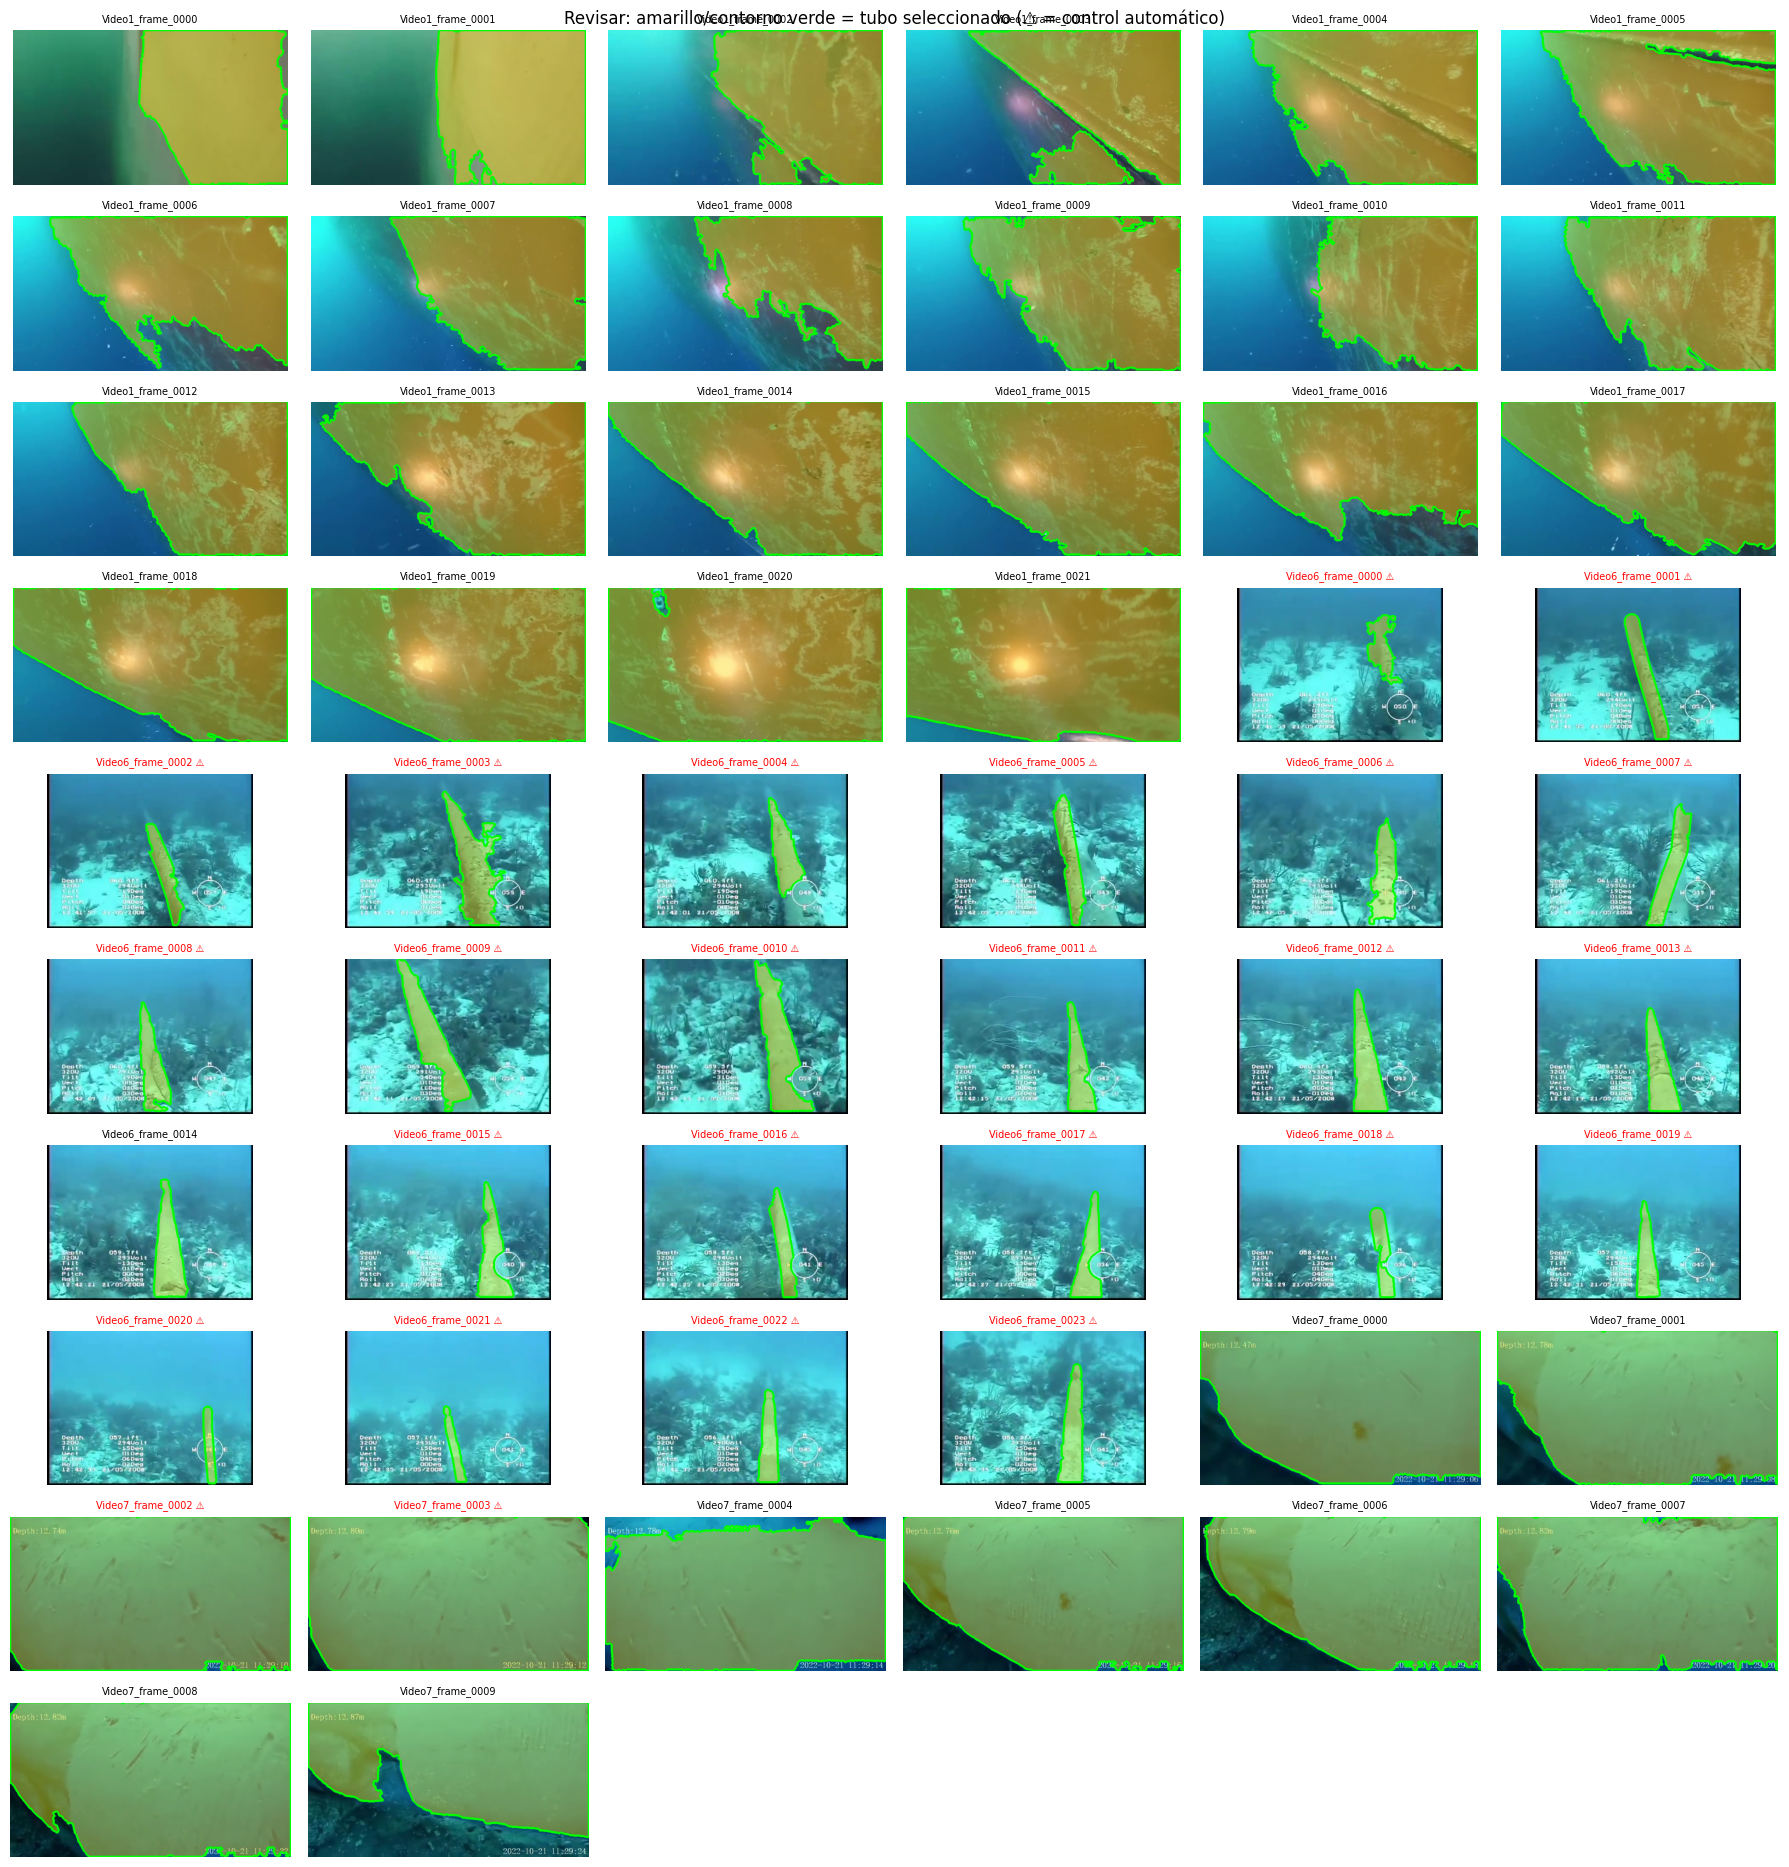

Frames etiquetados: 55 | rechazados: 1 | solo inferencia: 50


In [ ]:
TUBE_DIR=DATA/"TubeMasks"; TUBE_DIR.mkdir(parents=True,exist_ok=True)
tube_masks,tube_info={},[]
if LABEL_SOURCE=="sam_prompted":
    import hashlib
    kf_hash=hashlib.md5(json.dumps(TUBE_KEYFRAMES,sort_keys=True).encode()).hexdigest()
    stale=(TUBE_DIR/"keyframes_hash.txt").read_text()!=kf_hash if (TUBE_DIR/"keyframes_hash.txt").exists() else True
    pending=[v for v in LABEL_VIDEOS if RECOMPUTE_TUBE_MASKS or stale or
             any(not (TUBE_DIR/f"{n}_tube.png").exists() for n in names if video(n)==v)]
    if stale and (TUBE_DIR/"tube_info.csv").exists(): (TUBE_DIR/"tube_info.csv").unlink()
    if pending:
        torch.set_default_dtype(torch.float32)
        from segment_anything import sam_model_registry, SamPredictor
        ckpt=ROOT/Path(SAM_URL).name
        if not ckpt.exists():
            print("Descargando checkpoint SAM…"); urllib.request.urlretrieve(SAM_URL,ckpt)
        predictor=SamPredictor(sam_model_registry[SAM_MODEL](checkpoint=str(ckpt)).to(SAM_DEVICE))
        for v in pending:
            t0=time.time()
            frames=[(n,raw_full[n]) for n in names if video(n)==v]
            res=segment_video(frames,predictor,TUBE_KEYFRAMES)
            for n,(m,info) in res.items():
                cv2.imwrite(str(TUBE_DIR/f"{n}_tube.png"),m.astype(np.uint8)*255)
                tube_info.append(info)
            print(f"{v}: {len(frames)} frames en {time.time()-t0:.0f}s",flush=True)
        old=pd.read_csv(TUBE_DIR/"tube_info.csv") if (TUBE_DIR/"tube_info.csv").exists() else pd.DataFrame(columns=["frame"])
        new=pd.DataFrame(tube_info)
        pd.concat([old[~old.frame.isin(new.frame)],new]).to_csv(TUBE_DIR/"tube_info.csv",index=False)
        (TUBE_DIR/"keyframes_hash.txt").write_text(kf_hash)
        del predictor; torch.cuda.empty_cache() if torch.cuda.is_available() else None
    info_df=pd.read_csv(TUBE_DIR/"tube_info.csv") if (TUBE_DIR/"tube_info.csv").exists() else pd.DataFrame(columns=["frame"])
    for n in names:
        p=TUBE_DIR/f"{n}_tube.png"
        if video(n) in LABEL_VIDEOS and p.exists(): tube_masks[n]=cv2.imread(str(p),0)>0
else:
    info_df=pd.DataFrame(columns=["frame"])
    for n,p in drive_mask_paths.items():
        tube_masks[n]=clean_mask(read_drive_mask(p),valid_region(raw_full[n]))
torch.set_default_dtype(torch.float64)

# --- Controles de calidad ---
rows=[]
for n,m in tube_masks.items():
    valid=valid_region(raw_full[n]); r=dict(frame=n,video=video(n),occupancy=float(m[valid].mean()))
    if n in drive_mask_paths:
        r["iou_vs_drive_mask_v1"]=iou(m,read_drive_mask(drive_mask_paths[n]))
    rows.append(r)
audit=pd.DataFrame(rows).merge(info_df.drop(columns=["occupancy"],errors="ignore"),on="frame",how="left")
def flag(r):
    f=[]
    if r.occupancy<.02: f.append("casi vacía")
    if r.occupancy>.98: f.append("sin fondo visible (válido si el tubo llena el cuadro)")
    if r.get("iou_prev",1)==r.get("iou_prev",1) and r.get("iou_prev",1)<.6: f.append("salto vs frame anterior")
    if r.get("sam_score",1)==r.get("sam_score",1) and r.get("sam_score",1)<.8: f.append("score SAM bajo")
    return "; ".join(f)
audit["revisar"]=audit.apply(flag,axis=1)
audit["rechazado"]=audit.frame.isin(REJECT_FRAMES)|(audit.occupancy<.01)
audit.to_csv(OUT/"tube_audit.csv",index=False)
display(audit.round(3))
masks={n:m for n,m in tube_masks.items() if not audit.set_index("frame").loc[n,"rechazado"]}

# --- Rejilla de revisión: contorno verde = tubo seleccionado ---
lab_names=sorted(tube_masks); cols=6; rws=int(np.ceil(len(lab_names)/cols))
fig,axes=plt.subplots(rws,cols,figsize=(3*cols,1.9*rws),squeeze=False)
for ax,n in zip(axes.flat,lab_names):
    im=raw_full[n].copy(); m=tube_masks[n]
    im[m]=(.6*im[m]+.4*np.array([255,220,0])).astype(np.uint8)
    cnts,_=cv2.findContours(m.astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(im,cnts,-1,(0,255,0),3)
    ax.imshow(im); fl=audit.set_index("frame").loc[n,"revisar"]
    ax.set_title(n.replace("DeepWater-","")+(" ⚠" if fl else ""),fontsize=7,color="red" if fl else "black")
for ax in axes.flat: ax.axis("off")
plt.suptitle("Revisar: amarillo/contorno verde = tubo seleccionado (⚠ = control automático)")
plt.tight_layout(); plt.savefig(OUT/"tube_review.png",dpi=110); plt.show()
print("Frames etiquetados:",len(masks),"| rechazados:",int(audit.rechazado.sum()),"| solo inferencia:",len(names)-len(masks))

## 2b. Noise-reduction pipeline (“Noise Reduction” input)
Applied to **full-resolution raw images**, in this order:
1. **ROV spotlight glare** (Tab #8): very bright, low-saturation pixels (V > 235, S < 60), dilated and filled using Telea’s *inpainting* algorithm.
2. **Sea snow / particles**: *Non-Local Means* in color (`NLM_H`), which preserves the edges of the tube.
3. **Non-uniform illumination**: CLAHE applied to the L channel of Lab (does not alter the color balance; presentation, practical solution 1).

This is compared against Raw, CLAHE, MSRCR, and UDCP using the same labels, patches, and partition.

Antirruido aplicado a 105 frames en 43s


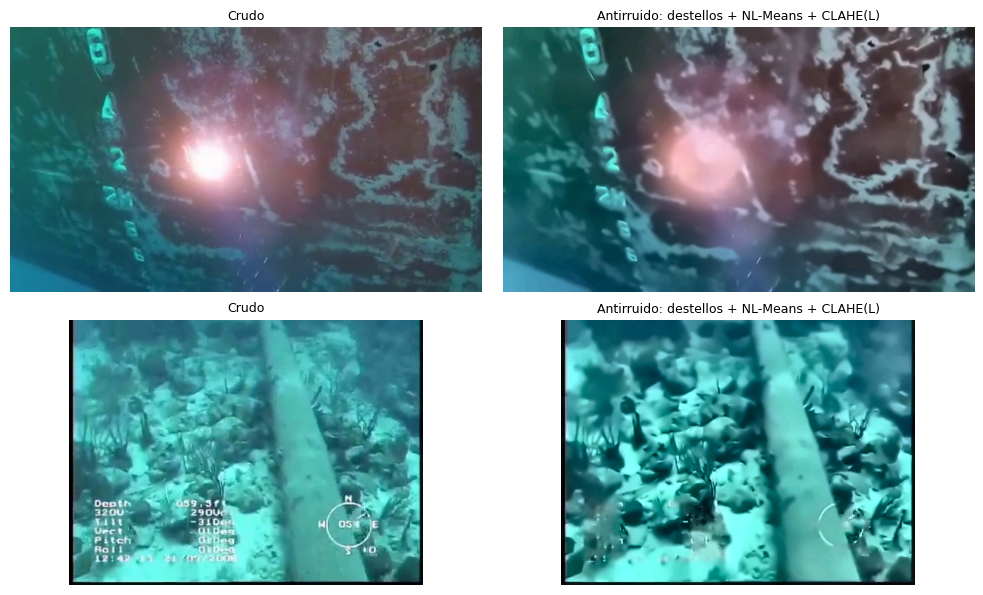

In [ ]:
def antinoise(rgb):
    hsv=cv2.cvtColor(rgb,cv2.COLOR_RGB2HSV)
    glare=((hsv[...,2]>235)&(hsv[...,1]<60)).astype(np.uint8)
    glare=cv2.dilate(glare,np.ones((5,5),np.uint8))
    x=cv2.inpaint(rgb,glare,5,cv2.INPAINT_TELEA) if glare.any() else rgb
    x=cv2.fastNlMeansDenoisingColored(x,None,NLM_H,NLM_H,7,21)
    lab=cv2.cvtColor(x,cv2.COLOR_RGB2LAB)
    lab[...,0]=cv2.createCLAHE(CLAHE_CLIP,CLAHE_TILES).apply(lab[...,0])
    return cv2.cvtColor(lab,cv2.COLOR_LAB2RGB)
t0=time.time()
antinoise_full={n:antinoise(raw_full[n]) for n in names}
images["Antirruido"]={n:small(antinoise_full[n]).astype(np.float32)/255 for n in names}
print(f"Antirruido aplicado a {len(names)} frames en {time.time()-t0:.0f}s")
ex=[n for n in names if "Video1_frame_0020" in n or "Video6_frame_0010" in n]
fig,axes=plt.subplots(len(ex),2,figsize=(10,3*len(ex)),squeeze=False)
for r,n in enumerate(ex):
    axes[r,0].imshow(raw_full[n]); axes[r,0].set_title("Crudo",fontsize=9)
    axes[r,1].imshow(antinoise_full[n]); axes[r,1].set_title("Antirruido: destellos + NL-Means + CLAHE(L)",fontsize=9)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.savefig(OUT/"antinoise_examples.png",dpi=120); plt.show()

## 3. Partitioning and Patches
`temporal_per_video`: Within **each** labeled video, time blocks ordered as 60/20/20 are used, with a one-frame gap between them. This ensures that all videos appear in the train, val, and test sets without sharing neighboring frames.
`by_video`: complete videos per partition (with 3 videos: one per split).
Generalization to new videos is measured separately using **leave-one-video-out** (Section 5b).

Label each patch based on the **actual fraction** of tube pixels (`INTER_AREA`): tube if ≥ `STRUCTURE_MIN`, background if ≤ `BACKGROUND_MAX`, and ambiguous (ignored) if between the two. Patches with more than 20% black border are also ignored.

**RandomResizedCrop augmentation** (training frames only): each frame generates `N_RRC` versions with random scaling by `RRC_SCALE` (zooming in or out with reflection-based padding). The image, mask, and valid region are transformed together, and the labels are recalculated using the same rule.

In [ ]:
labeled=sorted(masks)
vids=sorted({video(n) for n in labeled})
def temporal_split(frames):
    s={}
    for v in sorted({video(n) for n in frames}):
        seq=sorted(n for n in frames if video(n)==v)
        if len(seq)<10: raise ValueError(f"{v}: se requieren ≥10 frames para bloques temporales.")
        a,b=int(.6*len(seq)),int(.8*len(seq))
        for i,n in enumerate(seq):
            s[n]="gap" if i in (a,b) else "train" if i<a else "val" if i<b else "test"
    return s
if SPLIT_MODE=="by_video" and len(vids)>=3:
    order=list(np.random.default_rng(42).permutation(vids))
    split={n:"test" if video(n)==order[0] else "val" if video(n)==order[1] else "train" for n in labeled}
    split_note=f"Separación por videos completos (test={order[0]}, val={order[1]})."
else:
    split=temporal_split(labeled)
    split_note="Bloques temporales dentro de cada video (60/20/20, gap de 1 frame). Generalización entre videos: ver leave-one-video-out."
display(Markdown("**"+split_note+"**"))
pd.DataFrame([dict(frame=n,video=video(n),split=s) for n,s in split.items()]).to_csv(OUT/"split_manifest.csv",index=False)

coords=[(r,c) for r in range(0,SIZE_H-PATCH+1,PATCH) for c in range(0,SIZE_W-PATCH+1,PATCH)]
mask_small={n:small(masks[n].astype(np.float32)) for n in labeled}                       # fracción real
valid_small={n:small(valid_region(raw_full[n]).astype(np.float32)) for n in names}
records=[]
for n in labeled:
    for r,c in coords:
        occ=float(mask_small[n][r:r+PATCH,c:c+PATCH].mean())
        vf=float(valid_small[n][r:r+PATCH,c:c+PATCH].mean())
        label=-1 if vf<MIN_VALID else 1 if occ>=STRUCTURE_MIN else 0 if occ<=BACKGROUND_MAX else -1
        records.append(dict(frame=n,video=video(n),row=r,col=c,occupancy=occ,valid=vf,y=label,split=split[n]))
meta=pd.DataFrame(records)
meta.to_csv(OUT/"patch_manifest.csv",index=False)
y=meta.y.to_numpy()
idx={s:np.flatnonzero((meta.split==s)&(meta.y>=0)) for s in ["train","val","test"]}
for s,ii in idx.items():
    assert set(y[ii])=={0,1},f"{s} no contiene ambas clases. Revisar máscaras; no cambiar según rendimiento test."
display(pd.crosstab([meta.video,meta.split],meta.y).rename(columns={-1:"ignorado",0:"fondo",1:"tubo"}))

**Bloques temporales dentro de cada video (60/20/20, gap de 1 frame). Generalización entre videos: ver leave-one-video-out.**

y                       ignorado  fondo  tubo
video            split                       
DeepWater-Video1 gap           8     22    90
                 test          5     13   222
                 train        37    280   463
                 val          13     34   133
DeepWater-Video6 gap           3    107    10
                 test         13    217    10
                 train        52    656    72
                 val          17    208    15
DeepWater-Video7 gap           4      9   107
                 test          3     13    44
                 train        11     10   339
                 val           1      2    57

In [ ]:
from skimage.filters import sato
CANDIDATES=["L","a","b","L_std","a_std","b_std","gradiente","textura","saturacion",
            "dL_fondo","da_fondo","db_fondo","ctx_dL","ctx_da","ctx_db","coherencia","fila",
            "cresta_sato","textura_rel","z_L","z_sat","z_textura","z_gradiente","z_b","z_a"]
def patch_features(rgb):
    # Local (parche 16×16) + contexto (48×48) + normalización respecto al fondo del frame
    rgb=np.clip(rgb,0,1).astype(np.float32)
    lab=cv2.cvtColor(rgb,cv2.COLOR_RGB2LAB); L=lab[...,0]
    sat=cv2.cvtColor((rgb*255).astype(np.uint8),cv2.COLOR_RGB2HSV)[...,1].astype(np.float32)/255
    gx=cv2.Sobel(L,cv2.CV_32F,1,0,ksize=3); gy=cv2.Sobel(L,cv2.CV_32F,0,1,ksize=3); g=np.hypot(gx,gy)
    lap=cv2.Laplacian(L,cv2.CV_32F)
    med=np.median(lab.reshape(-1,3),0)                      # "fondo" del frame (SP-UIQA: desacoplar)
    k=np.ones((3*PATCH,3*PATCH),np.float32)/(9*PATCH*PATCH)
    ctx=np.stack([cv2.filter2D(lab[...,i],-1,k,borderType=cv2.BORDER_REFLECT) for i in range(3)],-1)
    rid=sato(L/100,sigmas=[1.5,2.5,4],black_ridges=False)          # tubos finos = crestas claras
    tex=lap**2; texc=cv2.filter2D(tex,-1,k,borderType=cv2.BORDER_REFLECT)
    out=[]
    for r,c in coords:
        s=np.s_[r:r+PATCH,c:c+PATCH]; P=lab[s].reshape(-1,3); m=P.mean(0); sd=P.std(0)
        a,b=gx[s],gy[s]; e=np.linalg.eigvalsh(np.array([[(a*a).sum(),(a*b).sum()],[(a*b).sum(),(b*b).sum()]]))
        cm=ctx[r+PATCH//2,c+PATCH//2]
        out.append([m[0],m[1],m[2],sd[0],sd[1],sd[2],np.log1p(g[s].mean()),np.log1p(lap[s].var()),sat[s].mean(),
                    *(m-med),*(cm-med),(e[1]-e[0])/(e[1]+e[0]+1e-6),r/SIZE_H,
                    rid[s].mean(),np.log1p(tex[s].mean())-np.log1p(texc[r+PATCH//2,c+PATCH//2])])
    out=np.array(out)
    # normalización DENTRO del frame (qué destaca respecto al resto de la escena)
    z=lambda v:(v-v.mean())/(v.std()+1e-6)
    return np.column_stack([out,z(out[:,0]),z(out[:,8]),z(out[:,7]),z(out[:,6]),z(out[:,2]),z(out[:,1])])
def patch_amplitudes(rgb):
    gray=cv2.cvtColor(np.clip(rgb,0,1).astype(np.float32),cv2.COLOR_RGB2GRAY)
    a=np.array([cv2.resize(gray[r:r+PATCH,c:c+PATCH],(8,8),interpolation=cv2.INTER_AREA).ravel() for r,c in coords],dtype=float)
    nrm=np.linalg.norm(a,axis=1,keepdims=True); z=nrm[:,0]<1e-12; a[z]=1/8; nrm[z]=1
    return a/nrm
def label_patches(mask_s,valid_s):
    ys=[]
    for r,c in coords:
        occ=mask_s[r:r+PATCH,c:c+PATCH].mean(); vf=valid_s[r:r+PATCH,c:c+PATCH].mean()
        ys.append(-1 if vf<MIN_VALID else 1 if occ>=STRUCTURE_MIN else 0 if occ<=BACKGROUND_MAX else -1)
    return np.array(ys)

t0=time.time()
FEAT={m:{n:patch_features(images[m][n]) for n in names} for m in METHODS}
AMP={m:{n:patch_amplitudes(images[m][n]) for n in names} for m in METHODS}
pos_in_frame=meta.groupby("frame").cumcount().to_numpy()
def stack(D,m): return np.stack([D[m][f][k] for f,k in zip(meta.frame,pos_in_frame)])
X_all={m:stack(FEAT,m) for m in METHODS}; X_amp={m:stack(AMP,m) for m in METHODS}
print(f"Características: {time.time()-t0:.0f}s")

# --- RandomResizedCrop sobre frames de train (imagen + máscara + región válida) ---
def rrc(img,mask,valid,rng):
    H,W=mask.shape; s=rng.uniform(*RRC_SCALE)
    if s<=1:
        ch,cw=int(H*np.sqrt(s)),int(W*np.sqrt(s)); y0=rng.integers(0,H-ch+1); x0=rng.integers(0,W-cw+1)
        sl=np.s_[y0:y0+ch,x0:x0+cw]; return img[sl],mask[sl],valid[sl]
    f=1/np.sqrt(s); nh,nw=int(H*f),int(W*f)
    t=rng.integers(0,H-nh+1); l=rng.integers(0,W-nw+1); pad=(t,H-nh-t,l,W-nw-l)
    rs=lambda a,it: cv2.resize(a,(nw,nh),interpolation=it)
    return (cv2.copyMakeBorder(rs(img,cv2.INTER_AREA),*pad,cv2.BORDER_REFLECT),
            cv2.copyMakeBorder(rs(mask.astype(np.uint8),cv2.INTER_NEAREST),*pad,cv2.BORDER_REFLECT).astype(bool),
            cv2.copyMakeBorder(rs(valid.astype(np.uint8),cv2.INTER_NEAREST),*pad,cv2.BORDER_REFLECT).astype(bool))
full_src={"Crudos":lambda n:raw_full[n],"Antirruido":lambda n:antinoise_full[n]}
AUG={m:dict(X=[],A=[],y=[],video=[]) for m in METHODS}
if N_RRC>0:
    t0=time.time()
    for m in METHODS:
        rng=np.random.default_rng(0)                 # misma geometría para todos los filtros
        for n in [n for n in labeled if split[n]=="train"]:
            img=full_src[m](n) if m in full_src else read_rgb(paths[m][n])
            for _ in range(N_RRC):
                im,mk,vd=rrc(img,masks[n],valid_region(raw_full[n]),rng)
                ims=small(im).astype(np.float32)/255
                yy=label_patches(small(mk.astype(np.float32)),small(vd.astype(np.float32))); keep=yy>=0
                AUG[m]["X"].append(patch_features(ims)[keep]); AUG[m]["A"].append(patch_amplitudes(ims)[keep])
                AUG[m]["y"].append(yy[keep]); AUG[m]["video"]+= [video(n)]*int(keep.sum())
        for k in ["X","A","y"]: AUG[m][k]=np.concatenate(AUG[m][k])
        AUG[m]["video"]=np.array(AUG[m]["video"])
    print(f"RRC: +{len(AUG[METHODS[0]]['y'])} parches de train por filtro ({time.time()-t0:.0f}s)")

class AngleScaler:
    # estandariza con estadísticas de TRAIN y mapea a ángulos en [-π/2, π/2]
    def fit(self,x): self.mu=x.mean(0); self.sd=x.std(0)+1e-8; return self
    def __call__(self,x): return np.clip((x-self.mu)/self.sd,-3,3)*np.pi/6

VIDEO=meta.video.to_numpy()
def video_weights(vv,yy):
    # cada combinación (video, clase) pesa lo mismo: Video6 (tubo fino, pocos parches) no queda aplastado por Video1
    if not BALANCE_BY_VIDEO: vv=np.zeros(len(yy),int)          # solo balance de clases (criterio global)
    w=np.ones(len(yy)); groups=[(v,c) for v in np.unique(vv) for c in (0,1) if ((vv==v)&(yy==c)).any()]
    for v,c in groups:
        k=(vv==v)&(yy==c); w[k]=len(yy)/(len(groups)*k.sum())
    return w
def macro_ba(yy,pp,vv):
    # balanced accuracy promedio por video (criterio de selección en validación)
    if not BALANCE_BY_VIDEO: return float(balanced_accuracy_score(yy,pp))
    return float(np.mean([balanced_accuracy_score(yy[vv==v],pp[vv==v]) for v in np.unique(vv) if len(set(yy[vv==v]))>1]))
def train_set(m,cols,use_rrc,tr_mask=None,amp=False):
    tr=idx["train"] if tr_mask is None else tr_mask
    Xb=(X_amp[m] if amp else X_all[m][:,cols])[tr]; yb=y[tr]; vb=VIDEO[tr]
    if use_rrc and N_RRC>0:
        vids_tr=set(VIDEO[tr]); sel=np.isin(AUG[m]["video"],list(vids_tr))
        Xa=(AUG[m]["A"] if amp else AUG[m]["X"][:,cols])[sel]
        Xb=np.vstack([Xb,Xa]); yb=np.r_[yb,AUG[m]["y"][sel]]; vb=np.r_[vb,AUG[m]["video"][sel]]
    return Xb,yb,vb

def svm_val(m,cols,use_rrc):
    Xtr,ytr,vtr=train_set(m,cols,use_rrc); sc=AngleScaler().fit(Xtr)
    best=(-1,None); va=idx["val"]
    for C in [.3,1,3,10]:
        s=SVC(C=C,kernel="rbf",gamma="scale").fit(sc(Xtr),ytr,sample_weight=video_weights(vtr,ytr))
        v=macro_ba(y[va],s.predict(sc(X_all[m][va][:,cols])),VIDEO[va])
        if v>best[0]: best=(v,C)
    return best

# --- Selección hacia adelante de N_QUBITS características; criterio: balanced accuracy de VALIDACIÓN promediada por video ---
SELECTED={}; USE_RRC={}; sel_rows=[]
for m in METHODS:
    t0=time.time(); cols=[]
    Xtr0=X_all[m][idx["train"]]; Xva0=X_all[m][idx["val"]]; w0=video_weights(VIDEO[idx["train"]],y[idx["train"]])
    for _ in range(N_QUBITS):
        best=(-1,None)
        for j in range(len(CANDIDATES)):
            if j in cols: continue
            cc=cols+[j]; sc=AngleScaler().fit(Xtr0[:,cc])
            s=SVC(C=3,kernel="rbf",gamma="scale").fit(sc(Xtr0[:,cc]),y[idx["train"]],sample_weight=w0)
            v=macro_ba(y[idx["val"]],s.predict(sc(Xva0[:,cc])),VIDEO[idx["val"]])
            if v>best[0]: best=(v,j)
        cols.append(best[1])
    SELECTED[m]=cols
    v0,_=svm_val(m,cols,False); v1,_=svm_val(m,cols,True) if N_RRC>0 else (-1,None)
    USE_RRC[m]=bool(v1>v0)
    sel_rows.append(dict(method=m,features=", ".join(CANDIDATES[j] for j in cols),valBA_macro_sin_RRC=v0,valBA_macro_con_RRC=v1,usa_RRC=USE_RRC[m],segundos=time.time()-t0))
sel_df=pd.DataFrame(sel_rows); sel_df.to_csv(OUT/"feature_selection.csv",index=False)
display(sel_df.round(3))
scalers={m:AngleScaler().fit(train_set(m,SELECTED[m],USE_RRC[m])[0]) for m in METHODS}
X_ang={m:scalers[m](X_all[m][:,SELECTED[m]]) for m in METHODS}
for m in METHODS: assert np.allclose(np.linalg.norm(X_amp[m],axis=1),1)

Características: 13s
RRC: +1803 parches de train por filtro (6s)


,method,features,valBA_macro_sin_RRC,valBA_macro_con_RRC,usa_RRC,segundos
0,Crudos,"db_fondo, L, dL_fondo, gradiente, ctx_db, z_gr...",0.936,0.932,False,12.669
1,CLAHE,"db_fondo, textura, fila, dL_fondo, z_L, textur...",0.943,0.924,False,12.181
2,MSRCR,"z_gradiente, z_b, saturacion, textura_rel, a_s...",0.939,0.918,False,15.251
3,UDCP,"db_fondo, gradiente, a, z_a, z_L, da_fondo, ct...",0.941,0.938,False,11.564
4,Antirruido,"db_fondo, fila, dL_fondo, saturacion, z_textur...",0.930,0.914,False,12.575


## 4. Models and Training
- **VQC-angles (main):** the 8 features selected during validation → `AngleEmbedding(RY)` before each of the 4 `StronglyEntanglingLayers` (*data re-uploading*), with a linear readout of ⟨Z⟩ from the 8 qubits. There are 96 quantum parameters and 9 classical parameters.
- **VQC-amplitudes (baseline v1):** 64 amplitudes, 6 qubits, 2 layers.
- **SVM-RBF** with **the same inputs** as each VQC.

Adam and BCE with **weights based on (video, class)**, so that Video6 (thin pipe, few patches) carries the same weight as Video1. Early stopping, the threshold, the filter, the features, and the post-processing are chosen based on the **balanced validation accuracy averaged across videos**. Training with RRC is performed only if validation improved for that filter.

In [ ]:
torch.set_default_dtype(torch.float64)
WIRES=list(range(N_QUBITS))
dev_ang=qml.device("default.qubit",wires=N_QUBITS)
@qml.qnode(dev_ang,interface="torch",diff_method="backprop")
def circuit_ang(x,w):
    for l in range(N_LAYERS):
        qml.AngleEmbedding(x,wires=WIRES,rotation="Y")          # re-uploading
        qml.StronglyEntanglingLayers(w[l:l+1],wires=WIRES)
    return [qml.expval(qml.PauliZ(i)) for i in WIRES]
dev_amp=qml.device("default.qubit",wires=6)
@qml.qnode(dev_amp,interface="torch",diff_method="backprop")
def circuit_amp(x,w):
    qml.AmplitudeEmbedding(x,wires=range(6),normalize=False)
    qml.StronglyEntanglingLayers(w,wires=range(6))
    return qml.expval(qml.PauliZ(0))

def init_params(kind,seed):
    g=torch.Generator().manual_seed(seed)
    if kind=="ang":
        return dict(w=torch.nn.Parameter(.1*torch.randn(N_LAYERS,N_QUBITS,3,generator=g)),
                    head=torch.nn.Parameter(.1*torch.randn(N_QUBITS,generator=g)),
                    bias=torch.nn.Parameter(torch.zeros(())))
    return dict(w=torch.nn.Parameter(.1*torch.randn(2,6,3,generator=g)))
def logits(kind,x,P):
    if kind=="ang":
        z=torch.stack(circuit_ang(x,P["w"]),-1)
        return z@P["head"]+P["bias"]
    p=((1+circuit_amp(x,P["w"]))/2).clamp(1e-6,1-1e-6)
    return torch.log(p/(1-p))
def predict_proba(kind,x,P):
    with torch.no_grad():
        return np.concatenate([torch.sigmoid(logits(kind,torch.tensor(x[i:i+256]),P)).numpy().reshape(-1)
                               for i in range(0,len(x),256)])
def metrics(yy,pp):
    return dict(accuracy=accuracy_score(yy,pp),balanced_accuracy=balanced_accuracy_score(yy,pp),
        precision=precision_score(yy,pp,zero_division=0),recall=recall_score(yy,pp,zero_division=0),
        f1=f1_score(yy,pp,zero_division=0),iou=jaccard_score(yy,pp,zero_division=0))
def best_threshold(yy,prob,vv):
    ts=np.linspace(.15,.85,29)
    return float(ts[np.argmax([macro_ba(yy,prob>=t,vv) for t in ts])])

def train_vqc(kind,xtr,ytr,vtr,xva,yva,vva,seed,log=True):
    P=init_params(kind,seed); opt=torch.optim.Adam(P.values(),lr=LR)
    xx=torch.tensor(xtr); yy=torch.tensor(ytr,dtype=torch.float64)
    ww=torch.tensor(video_weights(vtr,ytr))           # pesos por (video, clase)
    bce=torch.nn.BCEWithLogitsLoss(reduction="none")
    g=torch.Generator().manual_seed(seed)
    best,best_P,hist,wait=-1,None,[],0
    for epoch in range(1,EPOCHS+1):
        total=0.
        for b in torch.randperm(len(xx),generator=g).split(BATCH):
            opt.zero_grad(); loss=(bce(logits(kind,xx[b],P),yy[b])*ww[b]).mean(); loss.backward()
            assert all(torch.isfinite(p.grad).all() for p in P.values())
            opt.step(); total+=loss.item()*len(b)
        pv=predict_proba(kind,xva,P); vf=macro_ba(yva,pv>=.5,vva)  # BA promedio por video
        hist.append(dict(epoch=epoch,loss=total/len(xx),val_bal_acc=vf))
        if vf>best+1e-4: best,wait=vf,0; best_P={k:v.detach().clone() for k,v in P.items()}
        else: wait+=1
        if log and (epoch==1 or epoch%10==0): print(f"  {kind} seed={seed} ep={epoch} loss={total/len(xx):.4f} valBA={vf:.3f}",flush=True)
        if wait>=PATIENCE:
            if log: print(f"  early stopping en época {epoch} (mejor valBA={best:.3f})",flush=True)
            break
    thr=best_threshold(yva,predict_proba(kind,xva,best_P),vva)
    return best_P,thr,hist

def train_svm(xtr,ytr,vtr,xva,yva,vva):
    best,best_svm=-1,None
    for C in [.3,1,3,10,30]:
        s=SVC(C=C,kernel="rbf",gamma="scale").fit(xtr,ytr,sample_weight=video_weights(vtr,ytr))
        vf=macro_ba(yva,s.predict(xva),vva)
        if vf>best: best,best_svm=vf,s
    return best_svm

t0=time.perf_counter()
_P=init_params("ang",0); logits("ang",torch.tensor(X_ang["Crudos"][:4]),_P).sum().backward()
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in _P.values())
print(f"Gradiente/batching OK ({time.perf_counter()-t0:.2f}s)")
print(qml.draw(circuit_ang,max_length=120)(torch.zeros(N_QUBITS),_P["w"].detach()))

Gradiente/batching OK (0.10s)
0: ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M1)─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M2) ···
1: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M2) ···
2: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M2) ···
3: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M2) ···
4: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M2) ···
5: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M2) ···
6: ─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M1)─├AngleEmbedding(M0)─├StronglyEntanglingLayers(M2) ···
7: ─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M1)─╰AngleEmbedding(M0)─╰StronglyEntanglingLayers(M2) ···

0: ··· ─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M3)─╭AngleEmbedding(M0)─╭StronglyEntanglingLayers(M

In [ ]:
MODEL_SPECS=[("VQC-ángulos","ang"),("SVM-ángulos","svm_ang")]
if RUN_AMPLITUDE_BASELINE: MODEL_SPECS+=[("VQC-amplitudes (v1)","amp"),("SVM-amplitudes (v1)","svm_amp")]
models={}; histories={}; rows=[]; vrows=[]; pred_rows=[]; SCORES={}
def record(m,model,seed,score,pred,elapsed,thr):
    SCORES[(m,model,seed)]=score
    for s,ii in idx.items():
        rows.append(dict(method=m,model=model,seed=seed,split=s,seconds=elapsed,threshold=thr,
                         bal_acc_macro_video=macro_ba(y[ii],pred[ii],VIDEO[ii]),**metrics(y[ii],pred[ii])))
        for v in np.unique(VIDEO[ii]):
            jj=ii[VIDEO[ii]==v]
            vrows.append(dict(method=m,model=model,seed=seed,split=s,video=v,n_tubo=int(y[jj].sum()),n_fondo=int((y[jj]==0).sum()),**metrics(y[jj],pred[jj])))
        for j in ii:
            pred_rows.append(dict(method=m,model=model,seed=seed,patch_index=int(j),frame=meta.frame[j],split=s,
                                  y=int(y[j]),prediction=int(pred[j]),score=float(score[j])))
va=idx["val"]
for m in METHODS:
    print(f"\nENTRADA: {m} | RRC={'sí' if USE_RRC[m] else 'no'} | características: {[CANDIDATES[j] for j in SELECTED[m]]}",flush=True)
    models[m]={}
    Xtr_raw,ytr,vtr=train_set(m,SELECTED[m],USE_RRC[m]); Xtr=scalers[m](Xtr_raw)
    Atr,yatr,vatr=train_set(m,None,USE_RRC[m],amp=True)
    for name,kind in MODEL_SPECS:
        if kind.startswith("svm"):
            xtr,yt,vt,xall=(Xtr,ytr,vtr,X_ang[m]) if kind=="svm_ang" else (Atr,yatr,vatr,X_amp[m])
            t=time.perf_counter(); svm=train_svm(xtr,yt,vt,xall[va],y[va],VIDEO[va])
            models[m][name]=svm; joblib.dump(svm,OUT/f"{m}_{kind}.joblib")
            sc=svm.decision_function(xall); record(m,name,-1,1/(1+np.exp(-sc)),(sc>=0).astype(int),time.perf_counter()-t,np.nan)
            continue
        xtr,yt,vt,xall=(Xtr,ytr,vtr,X_ang[m]) if kind=="ang" else (Atr,yatr,vatr,X_amp[m])
        for seed in SEEDS:
            t=time.perf_counter()
            P,thr,h=train_vqc(kind,xtr,yt,vt,xall[va],y[va],VIDEO[va],seed)
            el=time.perf_counter()-t
            models[m][(name,seed)]=(P,thr); histories[(m,name,seed)]=h
            np.savez(OUT/f"{m}_{kind}_{seed}_params.npz",**{k:v.numpy() for k,v in P.items()},threshold=thr)
            prob=predict_proba(kind,xall,P); record(m,name,seed,prob,(prob>=thr).astype(int),el,thr)
    pd.DataFrame(rows).to_csv(OUT/"metrics.csv",index=False)
results=pd.DataFrame(rows); predictions=pd.DataFrame(pred_rows)
results_video=pd.DataFrame(vrows); results_video.to_csv(OUT/"metrics_by_video.csv",index=False)
predictions.to_csv(OUT/"patch_predictions.csv",index=False)
pd.concat([pd.DataFrame(h).assign(method=m,model=n,seed=s) for (m,n,s),h in histories.items()]).to_csv(OUT/"learning_curves.csv",index=False)


ENTRADA: Crudos | RRC=no | características: ['db_fondo', 'L', 'dL_fondo', 'gradiente', 'ctx_db', 'z_gradiente', 'z_b', 'saturacion']
  ang seed=17 ep=1 loss=0.6343 valBA=0.798
  ang seed=17 ep=10 loss=0.2490 valBA=0.879
  ang seed=17 ep=20 loss=0.2206 valBA=0.871
  ang seed=17 ep=30 loss=0.1995 valBA=0.854
  early stopping en época 38 (mejor valBA=0.913)
  ang seed=42 ep=1 loss=0.6123 valBA=0.800
  ang seed=42 ep=10 loss=0.2618 valBA=0.892
  ang seed=42 ep=20 loss=0.2226 valBA=0.915
  ang seed=42 ep=30 loss=0.2233 valBA=0.925
  ang seed=42 ep=40 loss=0.2008 valBA=0.915
  ang seed=101 ep=1 loss=0.6127 valBA=0.804
  ang seed=101 ep=10 loss=0.2659 valBA=0.881
  ang seed=101 ep=20 loss=0.2209 valBA=0.904
  early stopping en época 26 (mejor valBA=0.914)
  amp seed=17 ep=1 loss=0.6978 valBA=0.405
  amp seed=17 ep=10 loss=0.6821 valBA=0.399
  early stopping en época 16 (mejor valBA=0.494)
  amp seed=42 ep=1 loss=0.6956 valBA=0.457
  amp seed=42 ep=10 loss=0.6835 valBA=0.422
  early stopping 

## 5. Evaluation Deliverable
F1/IoU correspond to **patch-level classification (pipe/background)**, not pixel-by-pixel segmentation. The mean ± standard deviation across seeds is not a generalization confidence interval.

### Filtro seleccionado por validación: Crudos (semilla 42)
Bloques temporales dentro de cada video (60/20/20, gap de 1 frame). Generalización entre videos: ver leave-one-video-out.

**Test — balanced accuracy global y promedio por video (media de semillas)**

balanced_accuracy                                              \
model      SVM-amplitudes (v1) SVM-ángulos VQC-amplitudes (v1) VQC-ángulos   
method                                                                       
Antirruido               0.602       0.788               0.506       0.739   
CLAHE                    0.616       0.840               0.506       0.757   
Crudos                   0.574       0.867               0.479       0.786   
MSRCR                    0.596       0.847               0.555       0.808   
UDCP                     0.652       0.807               0.516       0.732   

           bal_acc_macro_video                                              \
model      SVM-amplitudes (v1) SVM-ángulos VQC-amplitudes (v1) VQC-ángulos   
method                                                                       
Antirruido               0.596       0.800               0.473       0.806   
CLAHE                    0.560       0.756               0.524       0.814   
Crudos                   0.514       0.752               0.504       0.797   
MSRCR                    0.564       0.784               0.503       0.775   
UDCP                     0.550       0.738               0.492       0.831   

                            f1                                              
model      SVM-amplitudes (v1) SVM-ángulos VQC-amplitudes (v1) VQC-ángulos  
method                                                                      
Antirruido               0.623       0.825               0.236       0.794  
CLAHE                    0.621       0.865               0.134       0.787  
Crudos                   0.614       0.889               0.031       0.830  
MSRCR                    0.718       0.867               0.378       0.836  
UDCP                     0.675       0.824               0.504       0.755

**Test por video** (la métrica global puede esconder un video que falla)

balanced_accuracy                                    \
video                   DeepWater-Video1 DeepWater-Video6 DeepWater-Video7   
method     model                                                             
Antirruido SVM-ángulos             0.957            0.729            0.712   
           VQC-ángulos             0.881            0.754            0.782   
CLAHE      SVM-ángulos             0.928            0.735            0.604   
           VQC-ángulos             0.878            0.822            0.742   
Crudos     SVM-ángulos             0.982            0.808            0.466   
           VQC-ángulos             0.962            0.801            0.628   
MSRCR      SVM-ángulos             0.955            0.853            0.543   
           VQC-ángulos             0.861            0.799            0.666   
UDCP       SVM-ángulos             0.928            0.746            0.540   
           VQC-ángulos             0.862            0.788            0.844   

                                 recall                                    \
video                  DeepWater-Video1 DeepWater-Video6 DeepWater-Video7   
method     model                                                            
Antirruido SVM-ángulos            0.914            0.800            0.886   
           VQC-ángulos            0.916            0.967            0.871   
CLAHE      SVM-ángulos            0.932            0.700            0.977   
           VQC-ángulos            0.808            0.967            0.894   
Crudos     SVM-ángulos            0.964            0.800            0.932   
           VQC-ángulos            0.923            0.967            1.000   
MSRCR      SVM-ángulos            0.910            0.900            0.932   
           VQC-ángulos            0.901            0.867            0.871   
UDCP       SVM-ángulos            0.856            0.700            0.773   
           VQC-ángulos            0.724            0.900            0.970   

                              precision                                    
video                  DeepWater-Video1 DeepWater-Video6 DeepWater-Video7  
method     model                                                           
Antirruido SVM-ángulos            1.000            0.098            0.867  
           VQC-ángulos            0.991            0.089            0.909  
CLAHE      SVM-ángulos            0.995            0.123            0.811  
           VQC-ángulos            0.996            0.121            0.882  
Crudos     SVM-ángulos            1.000            0.167            0.759  
           VQC-ángulos            1.000            0.111            0.822  
MSRCR      SVM-ángulos            1.000            0.176            0.788  
           VQC-ángulos            0.988            0.131            0.845  
UDCP       SVM-ángulos            1.000            0.135            0.791  
           VQC-ángulos            1.000            0.114            0.922

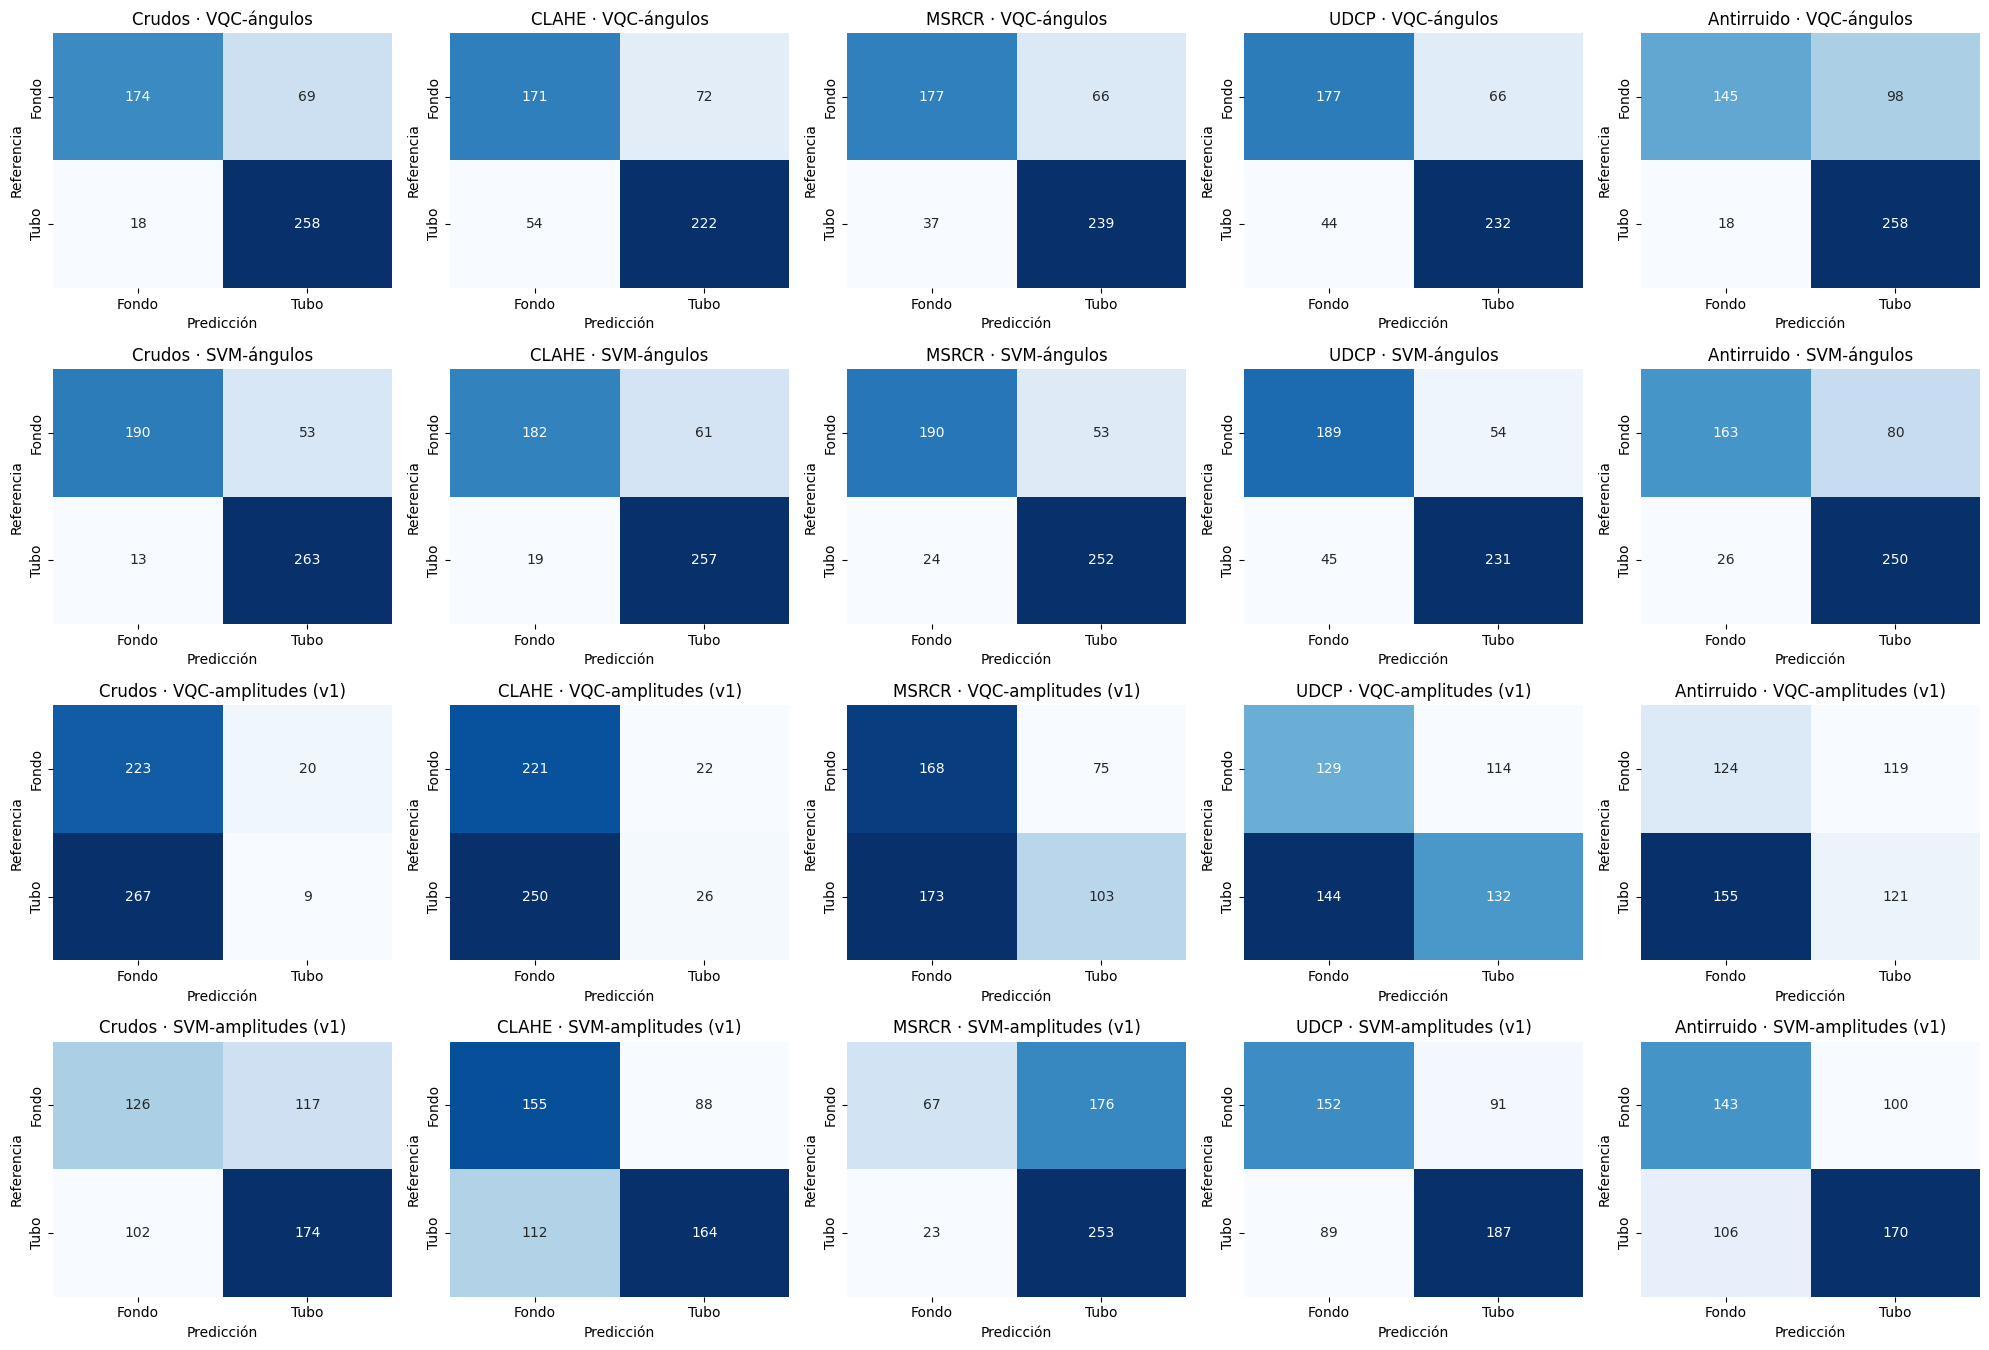

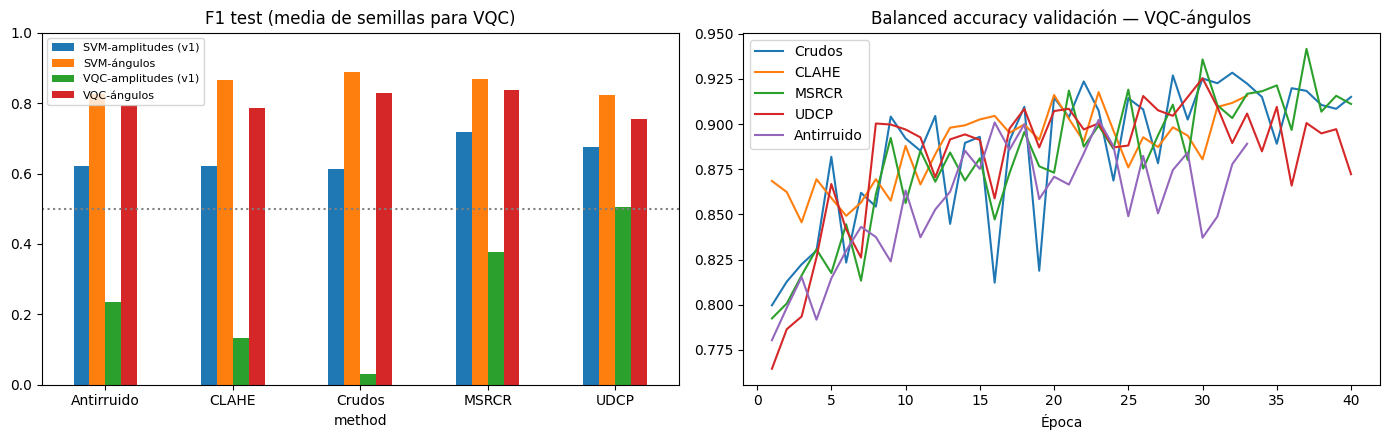

### Task 3.1: accuracy y matriz del VQC-ángulos

,split,accuracy,balanced_accuracy,bal_acc_macro_video,precision,recall,f1,threshold
3,train,0.8775,0.8809,0.9211,0.8127,0.9680,0.8836,0.425
4,val,0.8686,0.8771,0.9324,0.7874,0.9756,0.8715,0.425
5,test,0.8324,0.8254,0.8332,0.7890,0.9348,0.8557,0.425


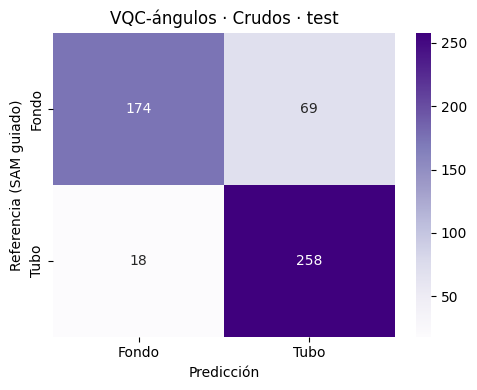

**Post-proceso elegido en validación:** ninguno (test no interviene en la elección)

,postproceso,threshold,val_BA_macro,test_BA,test_BA_macro,test_F1
0,ninguno,0.425,0.932,0.825,0.833,0.856
1,espacial,0.450,0.913,0.876,0.837,0.899
2,espacial+temporal,0.375,0.908,0.817,0.811,0.856


In [ ]:
MAIN="VQC-ángulos"
val=results[(results.split=="val")&(results.model==MAIN)]
chosen_method=val.groupby("method").bal_acc_macro_video.mean().idxmax()   # criterio: BA promedio por video (val)
def chosen_seed_for(m,model=MAIN):
    v=results[(results.split=="val")&(results.model==model)&(results.method==m)]
    return int(v.sort_values(["bal_acc_macro_video","seed"],ascending=[False,True]).iloc[0].seed)
chosen_seed=chosen_seed_for(chosen_method)
display(Markdown(f"### Filtro seleccionado por validación: {chosen_method} (semilla {chosen_seed})\n{split_note}"))
cols=["accuracy","balanced_accuracy","precision","recall","f1","iou"]
summary=results.groupby(["method","model","split"])[cols].agg(["mean","std"])
summary.to_csv(OUT/"comparison_summary.csv")
display(Markdown("**Test — balanced accuracy global y promedio por video (media de semillas)**"))
display(results[results.split=="test"].groupby(["method","model"])[["balanced_accuracy","bal_acc_macro_video","f1"]].mean().unstack("model").round(3))
display(Markdown("**Test por video** (la métrica global puede esconder un video que falla)"))
_rv=results_video[(results_video.split=="test")&(results_video.model.isin([MAIN,"SVM-ángulos"]))]
display(_rv.groupby(["method","model","video"])[["balanced_accuracy","recall","precision"]].mean().unstack("video").round(3))

model_names=[s[0] for s in MODEL_SPECS]
fig,axes=plt.subplots(len(model_names),len(METHODS),figsize=(4*len(METHODS),3.4*len(model_names)),squeeze=False)
for col,m in enumerate(METHODS):
    for row,mn in enumerate(model_names):
        sd=chosen_seed_for(m,mn) if mn.startswith("VQC") else -1
        p=predictions[(predictions.method==m)&(predictions.model==mn)&(predictions.seed==sd)&(predictions.split=="test")]
        cm=confusion_matrix(p.y,p.prediction,labels=[0,1])
        sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",cbar=False,ax=axes[row,col],xticklabels=["Fondo","Tubo"],yticklabels=["Fondo","Tubo"])
        axes[row,col].set(title=f"{m} · {mn}",xlabel="Predicción",ylabel="Referencia")
plt.tight_layout(); plt.savefig(OUT/"confusion_matrices.png",dpi=150); plt.show()

fig,axes=plt.subplots(1,2,figsize=(14,4.5))
results[results.split=="test"].groupby(["method","model"]).f1.mean().unstack().plot.bar(ax=axes[0],ylim=(0,1),rot=0)
axes[0].axhline(.5,ls=":",c="gray"); axes[0].set_title("F1 test (media de semillas para VQC)"); axes[0].legend(fontsize=8)
for m in METHODS:
    h=pd.DataFrame(histories[(m,MAIN,chosen_seed_for(m))]); axes[1].plot(h.epoch,h.val_bal_acc,label=m)
axes[1].legend(); axes[1].set(title=f"Balanced accuracy validación — {MAIN}",xlabel="Época")
plt.tight_layout(); plt.savefig(OUT/"comparison_and_training.png",dpi=160); plt.show()

selected=results[(results.method==chosen_method)&(results.model==MAIN)&(results.seed==chosen_seed)]
display(Markdown(f"### Task 3.1: accuracy y matriz del {MAIN}"))
display(selected[["split","accuracy","balanced_accuracy","bal_acc_macro_video","precision","recall","f1","threshold"]].round(4))
p=predictions[(predictions.method==chosen_method)&(predictions.model==MAIN)&(predictions.seed==chosen_seed)&(predictions.split=="test")]
fig,ax=plt.subplots(figsize=(5,4))
sns.heatmap(confusion_matrix(p.y,p.prediction,labels=[0,1]),annot=True,fmt="d",cmap="Purples",
    xticklabels=["Fondo","Tubo"],yticklabels=["Fondo","Tubo"],ax=ax)
ax.set(xlabel="Predicción",ylabel="Referencia (SAM guiado)",title=f"{MAIN} · {chosen_method} · test")
plt.tight_layout(); plt.savefig(OUT/"VQC_deliverable_confusion.png",dpi=200); plt.show()

# --- Post-proceso antirruido del mapa de predicción (espacial 3×3 y temporal EMA), elegido en VALIDACIÓN ---
R_,C_=SIZE_H//PATCH,SIZE_W//PATCH
KER=np.array([[1,1,1],[1,2,1],[1,1,1]],float); KER/=KER.sum()
frames_order=list(meta.frame.drop_duplicates())
def smooth(score,mode,alpha=.4):
    S=np.log(np.clip(score,1e-6,1-1e-6)/(1-np.clip(score,1e-6,1-1e-6))).reshape(len(frames_order),R_,C_)
    if mode in ("espacial","espacial+temporal"): S=np.stack([ndi.convolve(s,KER,mode="nearest") for s in S])
    if mode=="espacial+temporal":
        for i in range(1,len(S)):
            if video(frames_order[i])==video(frames_order[i-1]): S[i]=(1-alpha)*S[i]+alpha*S[i-1]
    return 1/(1+np.exp(-S.reshape(-1)))
sc_main=SCORES[(chosen_method,MAIN,chosen_seed)]
pp_rows=[]
for mode in ["ninguno","espacial","espacial+temporal"]:
    s=sc_main if mode=="ninguno" else smooth(sc_main,mode)
    vi,ti=idx["val"],idx["test"]
    thr=best_threshold(y[vi],s[vi],VIDEO[vi])
    pp_rows.append(dict(postproceso=mode,threshold=thr,val_BA_macro=macro_ba(y[vi],s[vi]>=thr,VIDEO[vi]),
                        test_BA=balanced_accuracy_score(y[ti],s[ti]>=thr),test_BA_macro=macro_ba(y[ti],s[ti]>=thr,VIDEO[ti]),
                        test_F1=f1_score(y[ti],s[ti]>=thr)))
pp_df=pd.DataFrame(pp_rows); pp_df.to_csv(OUT/"postprocessing.csv",index=False)
POSTPROC=pp_df.sort_values("val_BA_macro",ascending=False,kind="stable").iloc[0].postproceso
POST_THR=float(pp_df.set_index("postproceso").loc[POSTPROC,"threshold"])
display(Markdown(f"**Post-proceso elegido en validación:** {POSTPROC} (test no interviene en la elección)"))
display(pp_df.round(3))

## 5b. Generalization to new videos (leave-one-video-out)
With the chosen filter, training is performed using the remaining videos (their *train* and *val* blocks for early stopping and threshold) and evaluation is performed on the **complete** video that was left out. Feature scaling is readjusted without seeing the test video.

In [ ]:
lovo=[]
if len(vids)>=2:
    m=chosen_method; cols=SELECTED[m]
    for held in vids:
        trm=np.flatnonzero((meta.video!=held)&(meta.split=="train")&(meta.y>=0))
        vam=np.flatnonzero((meta.video!=held)&(meta.split=="val")&(meta.y>=0))
        tem=np.flatnonzero((meta.video==held)&(meta.y>=0))
        if len(set(y[tem]))<2 or len(set(y[vam]))<2:
            print(f"{held}: omitido (falta una clase)"); continue
        Xtr_raw,ytr,vtr=train_set(m,cols,USE_RRC[m],tr_mask=trm)          # RRC solo de los videos de train
        sc=AngleScaler().fit(Xtr_raw); xa=sc(X_all[m][:,cols])
        P,thr,_=train_vqc("ang",sc(Xtr_raw),ytr,vtr,xa[vam],y[vam],VIDEO[vam],chosen_seed,log=False)
        pv=(predict_proba("ang",xa[tem],P)>=thr).astype(int)
        lovo.append(dict(held_out=held,model=MAIN,**metrics(y[tem],pv)))
        svm=train_svm(sc(Xtr_raw),ytr,vtr,xa[vam],y[vam],VIDEO[vam])
        lovo.append(dict(held_out=held,model="SVM-ángulos",**metrics(y[tem],svm.predict(xa[tem]))))
        print(f"{held}: VQC BA={lovo[-2]['balanced_accuracy']:.3f} | SVM BA={lovo[-1]['balanced_accuracy']:.3f}",flush=True)
    lovo=pd.DataFrame(lovo); lovo.to_csv(OUT/"leave_one_video_out.csv",index=False)
    display(lovo.round(3))
    display(Markdown("Los tres videos son dominios muy distintos (casco en primer plano, tubería fina sobre arena, tubo gigante). "
                     "La LOVO mide ese salto de dominio; no se usa para elegir nada."))

DeepWater-Video1: VQC BA=0.333 | SVM BA=0.630
DeepWater-Video6: VQC BA=0.552 | SVM BA=0.580
DeepWater-Video7: VQC BA=0.504 | SVM BA=0.503


,held_out,model,accuracy,balanced_accuracy,precision,recall,f1,iou
0,DeepWater-Video1,VQC-ángulos,0.330,0.333,0.562,0.327,0.414,0.261
1,DeepWater-Video1,SVM-ángulos,0.518,0.630,0.893,0.378,0.531,0.361
2,DeepWater-Video6,VQC-ángulos,0.232,0.552,0.092,0.935,0.168,0.091
3,DeepWater-Video6,SVM-ángulos,0.229,0.580,0.097,1.000,0.177,0.097
4,DeepWater-Video7,VQC-ángulos,0.093,0.504,0.955,0.038,0.074,0.038
5,DeepWater-Video7,SVM-ángulos,0.117,0.503,0.947,0.066,0.123,0.066


Los tres videos son dominios muy distintos (casco en primer plano, tubería fina sobre arena, tubo gigante). La LOVO mide ese salto de dominio; no se usa para elegir nada.

## 6. Spatial predictions for ALL frames
Each filter uses the VQC angles selected during validation. The chosen filter also applies the post-processing method selected during validation. 16×16 block maps; green outline = reference tube; frames without a reference are based solely on inference.

Mapas completos: Crudos 105
Mapas completos: CLAHE 105
Mapas completos: MSRCR 105
Mapas completos: UDCP 105
Mapas completos: Antirruido 105


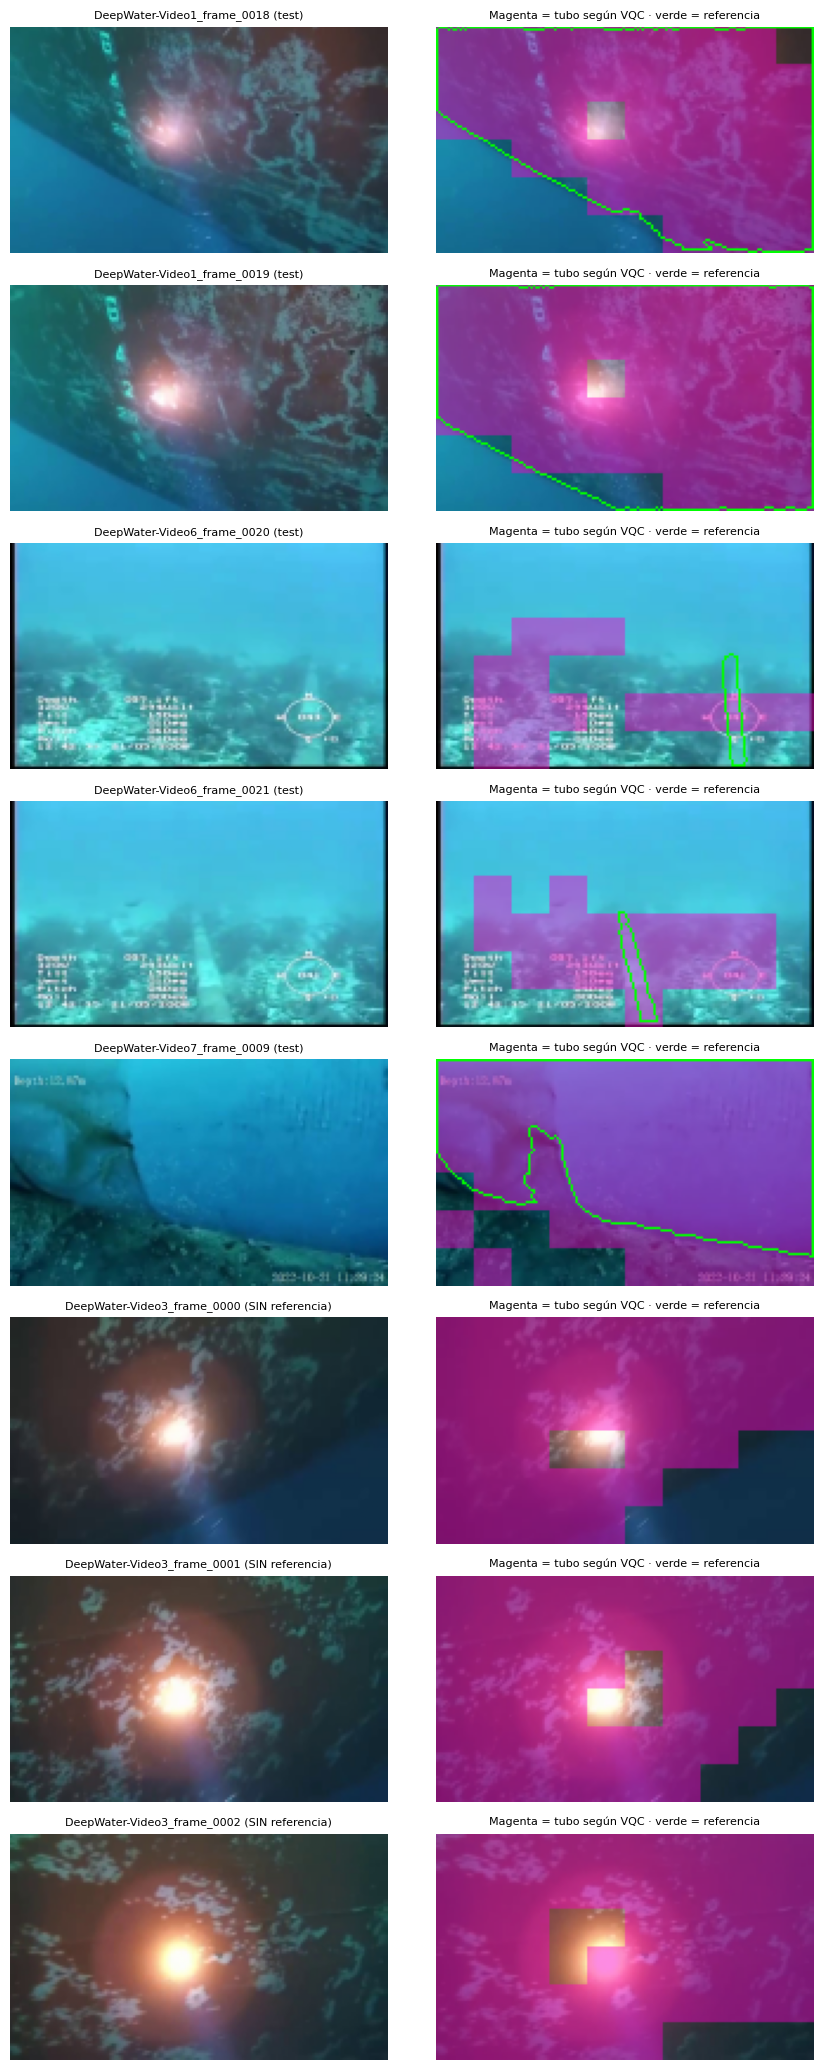

In [ ]:
inference=[]; maps={}
def to_map(v):
    mp=np.zeros((SIZE_H,SIZE_W),np.uint8)
    for (r,c),val in zip(coords,v): mp[r:r+PATCH,c:c+PATCH]=int(val)
    return mp
prev_logit={}
for m in METHODS:
    maps[m]={}; dest=OUT/"spatial_maps"/m; dest.mkdir(parents=True,exist_ok=True)
    P,thr=models[m][(MAIN,chosen_seed_for(m))]; svm=models[m]["SVM-ángulos"]
    use_pp=(m==chosen_method and POSTPROC!="ninguno")
    for n in names:
        xa=scalers[m](FEAT[m][n][:,SELECTED[m]])
        prob=predict_proba("ang",xa,P); th=thr
        if use_pp:
            S=np.log(np.clip(prob,1e-6,1-1e-6)/(1-np.clip(prob,1e-6,1-1e-6))).reshape(R_,C_)
            S=ndi.convolve(S,KER,mode="nearest")
            if POSTPROC=="espacial+temporal" and prev_logit.get(video(n)) is not None: S=.6*S+.4*prev_logit[video(n)]
            prev_logit[video(n)]=S; prob=1/(1+np.exp(-S.reshape(-1))); th=POST_THR
        vm=np.array([valid_small[n][r:r+PATCH,c:c+PATCH].mean()>=MIN_VALID for r,c in coords])
        pv=(prob>=th).astype(int)*vm; sv=svm.predict(xa)*vm
        maps[m][n]=to_map(pv)
        cv2.imwrite(str(dest/f"{n}_VQC.png"),maps[m][n]*255); cv2.imwrite(str(dest/f"{n}_SVM.png"),to_map(sv)*255)
        inference.append(dict(method=m,frame=n,video=video(n),usage=split.get(n,"solo_inferencia"),has_mask=n in masks,
            vqc_tube_fraction=float(pv[vm].mean()) if vm.any() else np.nan,svm_tube_fraction=float(sv[vm].mean()) if vm.any() else np.nan))
    print("Mapas completos:",m,len(names),flush=True)
pd.DataFrame(inference).to_csv(OUT/"all_frames_inference.csv",index=False)

def overlay(n,m):
    im=(np.clip(images[m][n],0,1)*255).astype(np.uint8).copy(); mp=maps[m][n].astype(bool)
    im[mp]=(.55*im[mp]+.45*np.array([255,0,200])).astype(np.uint8)
    if n in masks:
        cnts,_=cv2.findContours((mask_small[n]>=.5).astype(np.uint8),cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(im,cnts,-1,(0,255,0),1)
    return im
examples=[]
for v in vids: examples+=[n for n in labeled if video(n)==v and split[n]=="test"][:2]
examples+=[n for n in names if n not in masks][:3]
fig,axes=plt.subplots(len(examples),2,figsize=(9,2.6*len(examples)),squeeze=False)
for row,n in enumerate(examples):
    axes[row,0].imshow(np.clip(images[chosen_method][n],0,1)); axes[row,0].set_title(n+(" (test)" if n in masks else " (SIN referencia)"),fontsize=8)
    axes[row,1].imshow(overlay(n,chosen_method)); axes[row,1].set_title("Magenta = tubo según VQC · verde = referencia",fontsize=8)
for ax in axes.flat: ax.axis("off")
plt.tight_layout(); plt.savefig(OUT/"spatial_examples.png",dpi=150); plt.show()

In [ ]:
config=dict(version="v3-tube-fixed-antinoise",label_source=LABEL_SOURCE,label_videos=LABEL_VIDEOS,
    tube_keyframes=TUBE_KEYFRAMES,reject_frames=REJECT_FRAMES,sam_model=SAM_MODEL,
    size=[SIZE_W,SIZE_H],patch=PATCH,background_max=BACKGROUND_MAX,structure_min=STRUCTURE_MIN,min_valid=MIN_VALID,
    split_mode=SPLIT_MODE,split_note=split_note,n_qubits=N_QUBITS,n_layers=N_LAYERS,selected_features={m:[CANDIDATES[j] for j in SELECTED[m]] for m in METHODS},
    use_rrc=USE_RRC,rrc=dict(n=N_RRC,scale=RRC_SCALE),antinoise=dict(nlm_h=NLM_H,clahe_clip=CLAHE_CLIP,clahe_tiles=CLAHE_TILES),postprocessing=POSTPROC,
    seeds=SEEDS,epochs=EPOCHS,patience=PATIENCE,batch=BATCH,lr=LR,
    selected_method=chosen_method,selected_seed=chosen_seed,
    mask_status="SAM guiado por prompts + propagación; requiere revisión humana de tube_review.png")
(OUT/"config.json").write_text(json.dumps(config,indent=2,ensure_ascii=False))
(OUT/"requirements_executed.txt").write_text(subprocess.check_output([sys.executable,"-m","pip","freeze"],text=True))
test_tbl=results[results.split=="test"].groupby(["method","model"])[["balanced_accuracy","bal_acc_macro_video"]].mean().unstack("model").round(3)
_rvt=results_video[(results_video.split=="test")&(results_video.method==chosen_method)&(results_video.model.isin([MAIN,"SVM-ángulos"]))]
video_tbl=_rvt.groupby(["model","video"])[["balanced_accuracy","recall","precision"]].mean().round(3)
lovo_txt=lovo.groupby("model")[["balanced_accuracy","f1"]].mean().round(3).to_string() if isinstance(lovo,pd.DataFrame) and len(lovo) else "no calculado"
report=f'''# Task 3.1 — Quantum Patch Classifier (v3)
Etiquetas: tubo seleccionado con SAM guiado (keyframes + propagación) en {", ".join(LABEL_VIDEOS)}; {len(masks)} frames etiquetados.
VQC principal: 8 características elegidas en validación (de {len(CANDIDATES)}), angle encoding + re-uploading, {N_QUBITS} qubits, {N_LAYERS} capas.
Antirruido: destellos (inpainting) + NL-Means + CLAHE(L). RRC por filtro: {USE_RRC}. Post-proceso: {POSTPROC}.
Línea base: VQC de amplitudes de v1. Comparador: SVM-RBF con las mismas entradas (no QSVM).
Filtro seleccionado por validación: {chosen_method}; semilla: {chosen_seed}.
{split_note}
No se demuestra ventaja cuántica con estos resultados.

## {MAIN} seleccionado
{selected[["split","accuracy","balanced_accuracy","bal_acc_macro_video","f1"]].to_string(index=False)}

Post-proceso (elegido en validación):
{pp_df.round(3).to_string(index=False)}

## Test (media de semillas)
{test_tbl.to_string()}

## Test por video — filtro {chosen_method}
{video_tbl.to_string()}

## Leave-one-video-out (media)
{lovo_txt}

Revisión de etiquetas: tube_review.png / tube_audit.csv. Mapas: spatial_maps/.

## Guardar el entregable ejecutado en GitHub
Colab: Archivo → Guardar una copia en GitHub → rama feat/quantum-classification → 4_quantum_patch_classifier.ipynb.
No publicar datos originales sin permiso.
'''
(OUT/"README.md").write_text(report)
display(Markdown(report))
shutil.copytree(DATA/"TubeMasks",OUT/"tube_masks",dirs_exist_ok=True) if (DATA/"TubeMasks").exists() else None
archive=shutil.make_archive(str(OUT),"zip",OUT)
print("Resultados:",archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print("Fuera de Colab: usa la ruta anterior.")

# Task 3.1 — Quantum Patch Classifier (v3)
Etiquetas: tubo seleccionado con SAM guiado (keyframes + propagación) en DeepWater-Video1, DeepWater-Video6, DeepWater-Video7; 55 frames etiquetados.
VQC principal: 8 características elegidas en validación (de 25), angle encoding + re-uploading, 8 qubits, 4 capas.
Antirruido: destellos (inpainting) + NL-Means + CLAHE(L). RRC por filtro: {'Crudos': False, 'CLAHE': False, 'MSRCR': False, 'UDCP': False, 'Antirruido': False}. Post-proceso: ninguno.
Línea base: VQC de amplitudes de v1. Comparador: SVM-RBF con las mismas entradas (no QSVM).
Filtro seleccionado por validación: Crudos; semilla: 42.
Bloques temporales dentro de cada video (60/20/20, gap de 1 frame). Generalización entre videos: ver leave-one-video-out.
No se demuestra ventaja cuántica con estos resultados.

## VQC-ángulos seleccionado
split  accuracy  balanced_accuracy  bal_acc_macro_video       f1
train  0.877473           0.880916             0.921143 0.883551
  val  0.868597           0.877149             0.932392 0.871460
 test  0.832370           0.825416             0.833208 0.855721

Post-proceso (elegido en validación):
      postproceso  threshold  val_BA_macro  test_BA  test_BA_macro  test_F1
          ninguno      0.425         0.932    0.825          0.833    0.856
         espacial      0.450         0.913    0.876          0.837    0.899
espacial+temporal      0.375         0.908    0.817          0.811    0.856

## Test (media de semillas)
             balanced_accuracy                                             bal_acc_macro_video                                            
model      SVM-amplitudes (v1) SVM-ángulos VQC-amplitudes (v1) VQC-ángulos SVM-amplitudes (v1) SVM-ángulos VQC-amplitudes (v1) VQC-ángulos
method                                                                                                                                    
Antirruido               0.602       0.788               0.506       0.739               0.596       0.800               0.473       0.806
CLAHE                    0.616       0.840               0.506       0.757               0.560       0.756               0.524       0.814
Crudos                   0.574       0.867               0.479       0.786               0.514       0.752               0.504       0.797
MSRCR                    0.596       0.847               0.555       0.808               0.564       0.784               0.503       0.775
UDCP                     0.652       0.807               0.516       0.732               0.550       0.738               0.492       0.831

## Test por video — filtro Crudos
                              balanced_accuracy  recall  precision
model       video                                                 
SVM-ángulos DeepWater-Video1              0.982   0.964      1.000
            DeepWater-Video6              0.808   0.800      0.167
            DeepWater-Video7              0.466   0.932      0.759
VQC-ángulos DeepWater-Video1              0.962   0.923      1.000
            DeepWater-Video6              0.801   0.967      0.111
            DeepWater-Video7              0.628   1.000      0.822

## Leave-one-video-out (media)
             balanced_accuracy     f1
model                                
SVM-ángulos              0.571  0.277
VQC-ángulos              0.463  0.218

Revisión de etiquetas: tube_review.png / tube_audit.csv. Mapas: spatial_maps/.

## Guardar el entregable ejecutado en GitHub
Colab: Archivo → Guardar una copia en GitHub → rama feat/quantum-classification → 4_quantum_patch_classifier.ipynb.
No publicar datos originales sin permiso.


Resultados: /content/quantum_patch_classifier/results_20260929_144259.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Technical References

PennyLane. (n.d.). *AmplitudeEmbedding*. https://docs.pennylane.ai/en/stable/code/api/pennylane.AmplitudeEmbedding.html

PennyLane. (n.d.). *PyTorch interface*. https://docs.pennylane.ai/en/stable/introduction/interfaces/torch.html

This notebook implements a Variational Quantum Classifier (VQC) using **angle encoding with data re-uploading**, together with an **amplitude-encoding baseline**, one of the alternatives allowed for Task 3.1. The actual results are generated when the notebook is executed; **no metrics are preloaded or hard-coded**.

Kirillov, A., et al. (2023). *Segment Anything*. ICCV. https://github.com/facebookresearch/segment-anything

Pérez-Salinas, A., Cervera-Lierta, A., Gil-Fuster, E., & Latorre, J. I. (2020). Data re-uploading for a universal quantum classifier. *Quantum, 4*, 226.